# Degradation as Biomarker or Shortcut? — PART 1: Fundus arm (MIDL 2027)
**APTOS-2019 (train/val/test) -> Messidor-2 (external OOD)** · **six backbones** (ResNet-50, ConvNeXt-T, ViT-S/16, DenseNet-121, EfficientNet-B0, Swin-T) · arms: `baseline`, `harness`, `harness_ctrl` (shuffled-degradation control), `suppress` (ramped GRL, adversary monitored), and on ResNet-50 only `aug` (mild), `aug_strong`, `harness_brisque`

**Before running**
1. Settings → Internet **On** (pyiqa/timm weights). Accelerator: **GPU T4**. Add datasets: *APTOS-2019* and *messidor-2*.
2. **First run with `SMOKE = True`** (cell 1): ~15 min dry-run of every cell on tiny subsets, including downloading the pretrained weights of ALL six backbones. Fix anything it flags, then set `SMOKE = False` and *Save & Run All (Commit)*.
   The full run prints a **speed benchmark with a projected total time** before training starts. If it projects more than ~10 h, split `BACKBONES` over two sessions (first three / last three); Section 7 merges both outputs.
3. After the full run, the notebook **output** (`results_fundus.zip`, `preds_fundus_<backbone>.npz`) is what the CXR notebook mounts as an input for the combined decision-rule analysis.

**v5 changes vs v4 (arms, losses and hyper-parameters are UNCHANGED - no result-driven tuning):** (1) **5 seeds** (42, 7, 2024, 11, 99) instead of 3; (2) intervention predictions are now saved per image and per seed, and the harness model with its degradation channel zeroed/shuffled at test time is reported as arms `harness_zero` / `harness_shuffle` (Table 14); (3) **seed-aware pooled bootstrap** (Table 11b: resamples images AND seeds - quote these CIs); (4) the CXR notebook computes the pre-specified primary C3 test (Table 15: fundus-vs-CXR contrast of the test-time intervention drop). **All v4 checkpoints/results are superseded - run everything again.**

**Earlier changes (v3 vs the first results):** table-label misalignment in the probe table fixed; negative controls repeated 10x; seed-averaged *features* removed (invalid) → per-seed probes; forensic probes redesigned (within-domain, chance-corrected, R²); GradScaler added; all images decoded once into RAM (≈10x faster epochs); near-duplicate audit; harness control arm; degradation-only reference classifier; stratified/tercile AUC on ID and external; transfer-gap statistic with Holm correction; checkpoint round-trip guard that compares against the *logged* val AUC (data-agnostic).

In [1]:
!pip install -q pyiqa timm

import os, sys, glob, json, time, random, warnings, fnmatch, math, shutil
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as TF          # NOTE: the features DataFrame is called FD (no more F-shadowing)
import torchvision.transforms as T
from PIL import Image, ImageEnhance, ImageFilter
from scipy import ndimage
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import make_pipeline
from sklearn.manifold import TSNE
from sklearn.metrics import (roc_auc_score, average_precision_score, cohen_kappa_score,
                             balanced_accuracy_score, accuracy_score)

warnings.filterwarnings('ignore')
def _clip8(z): return np.clip(z, -8, 8)       # guards the probes against (near-)constant feature dimensions blowing up after z-scoring

# =============================== CONFIG ===============================
SMOKE = False        # True = ~15 min end-to-end dry run (ALL backbones, tiny subsets, 1 epoch). RUN THIS FIRST, then set False.
SEEDS = [42, 7, 2024, 11, 99]     # v5: 5 seeds (v4: 3). CXR external AUC varied by up to 0.06 between seeds; more seeds = tighter, seed-aware CIs
EPOCHS = 15
BS = 32
N_WORKERS = 4
TIME_BUDGET_H = 10.5              # no new training run is launched after this many hours (Kaggle session limit = 12 h)

# six backbones from five different families (timm names). Order = priority if the time budget runs out.
BACKBONES = ['resnet50', 'convnext_tiny', 'vit_small_patch16_224', 'densenet121', 'efficientnet_b0', 'swin_tiny_patch4_window7_224']
#   resnet50 / densenet121 / efficientnet_b0 : CNN with BatchNorm   (residual / dense / depthwise-MBConv)
#   convnext_tiny                            : CNN with LayerNorm (no BatchNorm)
#   vit_small_patch16_224                    : plain transformer (global attention, no BatchNorm)
#   swin_tiny_patch4_window7_224             : hierarchical windowed transformer
# To split the work over TWO Kaggle sessions (recommended if the benchmark below projects > 10 h):
#   session A: BACKBONES = first three, session B: BACKBONES = last three; the final aggregation cell merges both outputs.
LR_BB = {'resnet50': 3e-5, 'convnext_tiny': 3e-5, 'vit_small_patch16_224': 3e-5,
         'densenet121': 5e-5, 'efficientnet_b0': 1e-4, 'swin_tiny_patch4_window7_224': 3e-5}   # fine-tuning LR of the backbone (heads: 1e-3)
AUG_BACKBONES = ['resnet50']      # augmentation arms + the BRISQUE-only harness ablation are run on these backbones only
CORE_ARMS = ['baseline', 'harness', 'harness_ctrl', 'suppress']
#   harness_ctrl = harness architecture fed SHUFFLED degradation vectors (controls for the extra parameters)
EXTRA_ARMS = ['aug', 'aug_strong', 'harness_brisque']
#   aug            = MILD, lesion-safe augmentation (gamma/contrast +-20-25 %, blur & noise applied to 30 % of images and weak) = the fair augmentation baseline
#   aug_strong     = the v3 augmentation (always-on blur sigma up to 2 px + noise) = sensitivity analysis (it erases microaneurysms)
#   harness_brisque= harness that sees ONLY BRISQUE (1 of 11 features): tests whether the benefit comes from the single quality score
ARMS_FOR = {b: CORE_ARMS + (EXTRA_ARMS if b in AUG_BACKBONES else []) for b in BACKBONES}
PROBE_SEEDS_N = 3                 # forensic probes are run on the first N seeds only (cost control)
N_SMOKE = 120                     # images per split in SMOKE mode
LAM = 1.0                         # final GRL strength; it is RAMPED 0 -> LAM during training (DANN schedule), see train_arm
ADV_W = 0.5                       # adversarial loss weight (v3: 1.0 constant -> the ConvNeXt adversary collapsed below chance)
ADV_TOL = 0.10                    # a suppress epoch is 'eligible' for checkpoint selection only if |val adversary acc - 0.20| <= ADV_TOL
SEED = 42
# ======================================================================
if SMOKE:
    SEEDS, EPOCHS, PROBE_SEEDS_N = SEEDS[:1], 1, 1

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'
TOP = '/kaggle/working'
WORK = TOP + ('/smoke' if SMOKE else '')
# checkpoints go to /kaggle/temp (NOT saved with the notebook output -> output stays small); fall back to working dir elsewhere
CKPT_ROOT = '/kaggle/temp' if os.path.isdir('/kaggle/temp') else TOP
RES, CKPT, FEAT = f'{WORK}/results', f'{CKPT_ROOT}/ckpt' + ('_smoke' if SMOKE else ''), f'{WORK}/features'
for d in (RES, CKPT, FEAT):
    os.makedirs(d, exist_ok=True)
INPUT = '/kaggle/input'
T0 = time.time()
print('device:', DEVICE, '| SMOKE:', SMOKE, '| seeds:', SEEDS, '| epochs:', EPOCHS)
print('backbones:', {b: ARMS_FOR[b] for b in BACKBONES})

# ---- dataset configuration (FUNDUS arm) ----
TAG = 'fundus'
SRC_TR, SRC_VA, SRC_TE, SRC_EX = 'aptos_train', 'aptos_val', 'aptos_test', 'messidor'
NAME_ID, NAME_EX, TASK = 'APTOS-2019', 'Messidor-2', 'referable DR'


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 10.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 96.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 50.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.3/226.3 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 104.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.5/99.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

## 1. Data discovery + splits
Publisher's `valid.csv/test.csv` are **not** used for training/selection; they become an audit set (Section 7b). Val/test are carved (stratified 70/15/15) from `train_1.csv` as in the paper protocol.

In [2]:
def walk_input():
    for root, dirs, files in os.walk(INPUT):
        yield root, dirs, files

def find_dirs(patterns):
    hits = []
    for root, dirs, _ in walk_input():
        for d in dirs:
            if any(fnmatch.fnmatch(d.lower(), p) for p in patterns):
                hits.append(os.path.join(root, d))
    return hits

def find_files(patterns):
    hits = []
    for root, _, files in walk_input():
        for f in files:
            if any(fnmatch.fnmatch(f.lower(), p) for p in patterns):
                hits.append(os.path.join(root, f))
    return hits

train_dirs = find_dirs(['train*'])
val_dirs   = [d for d in find_dirs(['val*', 'valid*']) if 'train' not in os.path.basename(d).lower()]
test_dirs  = [d for d in find_dirs(['test*']) if 'train' not in os.path.basename(d).lower()]
mess_root  = [d for d in find_dirs(['messidor*']) if os.path.exists(os.path.join(d, 'messidor_data.csv'))]
assert train_dirs and mess_root, 'Could not locate APTOS train_images or messidor_data.csv - check dataset names.'
mess_img_root = os.path.dirname(mess_root[0])
all_csvs   = find_files(['*.csv'])
aptos_csvs = [c for c in all_csvs if 'messidor' not in c.lower().replace('_', '')]
print('train_dirs :', train_dirs); print('messidor   :', mess_root); print('aptos csvs :', aptos_csvs)

IMG_EXT = ('.png', '.jpg', '.jpeg', '.tif', '.tiff')
def norm_id(v):
    v = os.path.basename(str(v).strip()).lower()
    v = os.path.splitext(v)[0]
    return ''.join(ch for ch in v if ch.isalnum())

def id2path_map(dirs):
    m = {}
    for d in dirs:
        for p in glob.glob(os.path.join(d, '**', '*.*'), recursive=True):
            if p.lower().endswith(IMG_EXT):
                m[norm_id(p)] = p
    return m

def pick_id_col(df, idmap):
    keys = set(idmap.keys()); best_c, best_s = None, 0.0
    for c in df.columns:
        s = float(df[c].astype(str).map(norm_id).isin(keys).mean())
        if s > best_s:
            best_c, best_s = c, s
    return best_c, best_s

train_map, val_map, test_map = id2path_map(train_dirs), id2path_map(val_dirs), id2path_map(test_dirs)
mess_map = {norm_id(p): p for p in glob.glob(os.path.join(mess_img_root, '**', '*.*'), recursive=True)
            if p.lower().endswith(IMG_EXT)}
print('images: aptos train/val/test dirs =', len(train_map), len(val_map), len(test_map), '| messidor =', len(mess_map))

def norm(s): return str(s).strip().lower().replace('_', '').replace(' ', '').replace('-', '')
LAB_CANDS = [norm(c) for c in ['diagnosis', 'adjudicated_dr_grade', 'retinopathy_grade', 'dr_grade',
                               'diabetic_retinopathy', 'level', 'label', 'grade', 'dr', 'target']]

def pick_label_col(df):
    for c in df.columns:
        if norm(c) in LAB_CANDS and pd.api.types.is_numeric_dtype(df[c]):
            vals = pd.to_numeric(df[c], errors='coerce').dropna().unique()
            if len(vals) and vals.min() >= 0 and vals.max() <= 4:
                return c
    best, bs = None, 1e9
    for c in df.columns:
        if pd.api.types.is_numeric_dtype(df[c]):
            u = df[c].dropna().unique()
            if 1 < len(u) <= 10 and len(u) < bs:
                best, bs = c, len(u)
    if best is not None:
        print(f'  WARNING: label column "{best}" chosen by heuristic, verify it is the DR grade.')
    return best

def load_csv(path):
    for sep in [',', ';', '\t']:
        try:
            df = pd.read_csv(path, sep=sep)
            if df.shape[1] > 1:
                return df
        except Exception:
            continue
    raise ValueError(f'cannot read {path}')

def build_frame(csv_path, idmap, source):
    df = load_csv(csv_path)
    idc, rate = pick_id_col(df, idmap)
    print(f'[{source}] csv={os.path.basename(csv_path)} cols={list(df.columns)}')
    print(f'[{source}] id column="{idc}" (filename match rate={rate:.1%})')
    assert idc is not None and rate > 0.5, f'[{source}] could not match CSV ids to image files.'
    lab = pick_label_col(df)
    print(f'[{source}] label column="{lab}"')
    assert lab is not None, f'[{source}] no label column found - extend LAB_CANDS manually.'
    out = pd.DataFrame({'id': df[idc].astype(str).map(norm_id), 'grade': pd.to_numeric(df[lab], errors='coerce')})
    out['path'] = out['id'].map(idmap)
    out = out.dropna(subset=['path', 'grade']).drop_duplicates('id')
    out['source'] = source
    out['label'] = (out['grade'] >= 2).astype(int)        # referable DR = moderate NPDR or worse
    return out.reset_index(drop=True)

def find_csv(names):
    for n in names:
        for p in aptos_csvs:
            if os.path.basename(p).lower() == n:
                return p
    return None

# ---------- labelled pool (train_1.csv) -> stratified 70/15/15 carve (the paper's protocol) ----------
tr_pool = build_frame(find_csv(['train_1.csv', 'train.csv']), train_map, 'aptos_pool')
print('[pool] grade counts:\n' + tr_pool['grade'].value_counts().sort_index().to_string())

def stratified_carve(df, frac_val=0.15, frac_test=0.15):
    tr_l, va_l, te_l = [], [], []
    for lab, grp in df.groupby('label'):
        grp = grp.sample(frac=1.0, random_state=SEED); n = len(grp)
        n_te = max(2, int(round(n * frac_test))); n_va = max(2, int(round(n * frac_val)))
        te_l.append(grp.iloc[:n_te]); va_l.append(grp.iloc[n_te:n_te + n_va]); tr_l.append(grp.iloc[n_te + n_va:])
    return (pd.concat(tr_l).sample(frac=1.0, random_state=SEED).reset_index(drop=True),
            pd.concat(va_l).reset_index(drop=True), pd.concat(te_l).reset_index(drop=True))

tr, va, te = stratified_carve(tr_pool)
tr['source'], va['source'], te['source'] = SRC_TR, SRC_VA, SRC_TE

# ---------- OFFICIAL valid/test csvs: kept as an AUDIT set (see Section 7b), NOT used for training/selection ----------
# The earlier "valid ~0.97 / test ~0.26-0.66" chaos came from the backbone-only checkpoint bug (random heads at
# evaluation), NOT necessarily from bad labels. With the fixed pipeline we re-test the official split instead of
# assuming it is broken.
aud = None
try:
    cs = find_csv(['test.csv'])
    if cs is not None and len(test_map):
        aud = build_frame(cs, test_map, 'aptos_official_test'); aud['source'] = 'aptos_official_test'
        print('[audit] official test.csv frame:', len(aud), 'pos_rate=%.3f' % aud.label.mean())
except Exception as e:
    print('[audit] official test split not usable (non-fatal):', e)

# ---------- Messidor-2 (external, never used for fitting/selection) ----------
mdf = load_csv(os.path.join(mess_root[0], 'messidor_data.csv'))
midc, mrate = pick_id_col(mdf, mess_map)
print(f'[messidor] cols={list(mdf.columns)} id column="{midc}" (match rate={mrate:.1%})')
assert midc is not None and mrate > 0.5, 'messidor: could not match CSV ids to image files.'
mlab = pick_label_col(mdf)
print(f'[messidor] label column="{mlab}"')
assert mlab is not None, 'messidor: no label column found - extend LAB_CANDS manually.'
me = pd.DataFrame({'id': mdf[midc].astype(str).map(norm_id), 'grade': pd.to_numeric(mdf[mlab], errors='coerce')})
me['path'] = me['id'].map(mess_map)
me = me.dropna(subset=['path', 'grade']).drop_duplicates('id')
me['source'] = SRC_EX
me['label'] = (me['grade'] >= 2).astype(int)
me = me.reset_index(drop=True)

if SMOKE:   # tiny stratified subsets for the dry run
    def _sub(d, n=N_SMOKE):
        return pd.concat([g.head(n // 2) for _, g in d.groupby('label')]).reset_index(drop=True)
    tr, va, te, me = _sub(tr), _sub(va), _sub(te), _sub(me)
    if aud is not None: aud = _sub(aud)
assert not (set(tr['id']) & set(va['id'])) and not (set(tr['id']) & set(te['id'])) and not (set(va['id']) & set(te['id'])), \
    'carved splits must be disjoint'
for name, d in [('train', tr), ('val', va), ('test', te), ('messidor', me)]:
    print(f'{name:9s} n={len(d):5d}  pos_rate={d.label.mean():.3f}  grades={sorted(d.grade.unique())}')
assert len(me) > 0, 'messidor frame is empty after matching.'


train_dirs : ['/kaggle/input/datasets/mariaherrerot/aptos2019/train_images', '/kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images']
messidor   : ['/kaggle/input/datasets/xyaustin/messidor2/messidor-2']
aptos csvs : ['/kaggle/input/datasets/mariaherrerot/aptos2019/valid.csv', '/kaggle/input/datasets/mariaherrerot/aptos2019/test.csv', '/kaggle/input/datasets/mariaherrerot/aptos2019/train_1.csv']
images: aptos train/val/test dirs = 2930 366 366 | messidor = 1748
[aptos_pool] csv=train_1.csv cols=['id_code', 'diagnosis']
[aptos_pool] id column="id_code" (filename match rate=100.0%)
[aptos_pool] label column="diagnosis"
[pool] grade counts:
grade
0    1434
1     300
2     808
3     154
4     234
[aptos_official_test] csv=test.csv cols=['id_code', 'diagnosis']
[aptos_official_test] id column="id_code" (filename match rate=100.0%)
[aptos_official_test] label column="diagnosis"
[audit] official test.csv frame: 366 pos_rate=0.374
[messidor] cols=['image_id', 'adjudicated_dr

## 1b. Image bank (decode once) + near-duplicate audit

In [3]:
# ---- decode every image ONCE into a 256x256 uint8 array bank (RAM). Training then needs no disk/JPEG decoding. ----
IMG_SIZE = 256
def load_resized(p):
    with Image.open(p) as im:
        return np.asarray(im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

_frames = [tr, va, te, me] + ([aud] if aud is not None else [])
BANK_PATHS = list(dict.fromkeys(pd.concat(_frames)['path'].tolist()))
PATH2ROW = {p: i for i, p in enumerate(BANK_PATHS)}
t0 = time.time()
BANK = np.empty((len(BANK_PATHS), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
with ThreadPoolExecutor(8) as pool:
    for i, a in enumerate(pool.map(load_resized, BANK_PATHS)):
        BANK[i] = a
        if i % 500 == 0:
            print(f'  bank {i}/{len(BANK_PATHS)}', end='\r')
print(f'image bank: {BANK.shape}  {BANK.nbytes/1e9:.2f} GB  ({time.time()-t0:.0f}s)')


image bank: (5040, 256, 256, 3)  0.99 GB  (187s)


  threshold 0.95: val removed 164, test removed 204
  threshold 0.97: val removed 75, test removed 105
  threshold 0.98: val removed 35, test removed 54
  threshold 0.99: val removed 15, test removed 22
  threshold 0.995: val removed 14, test removed 21


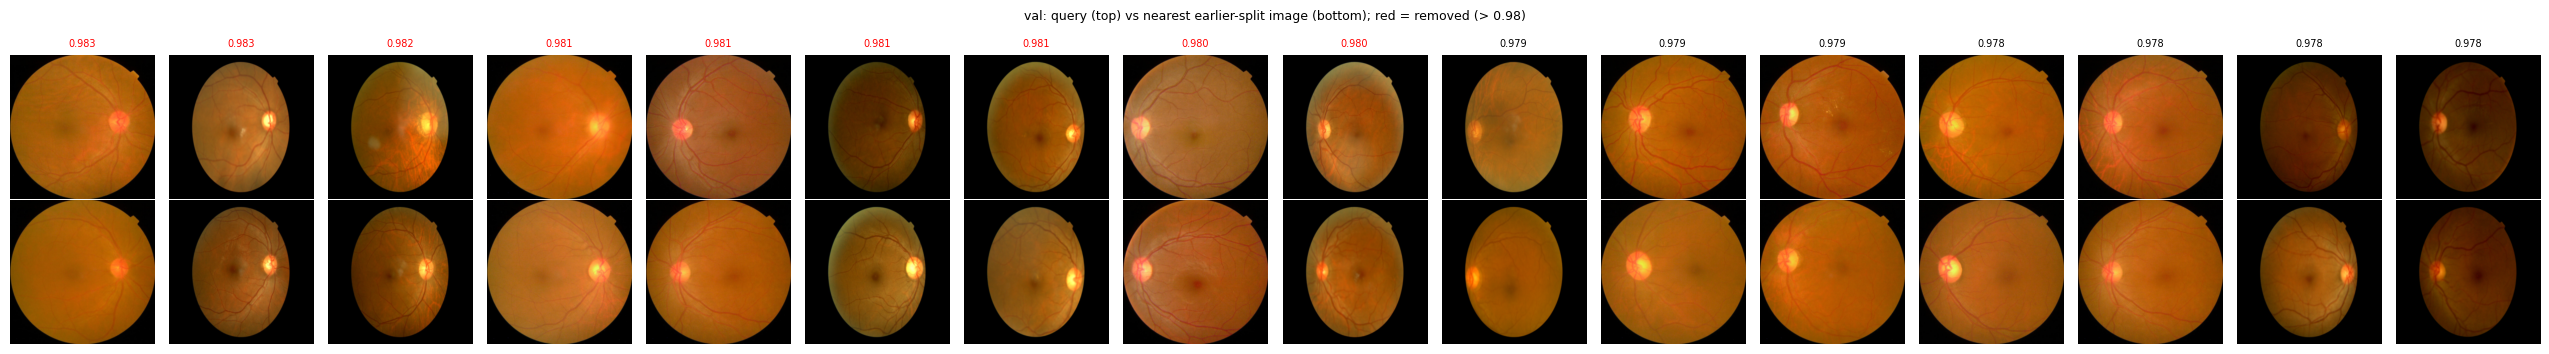

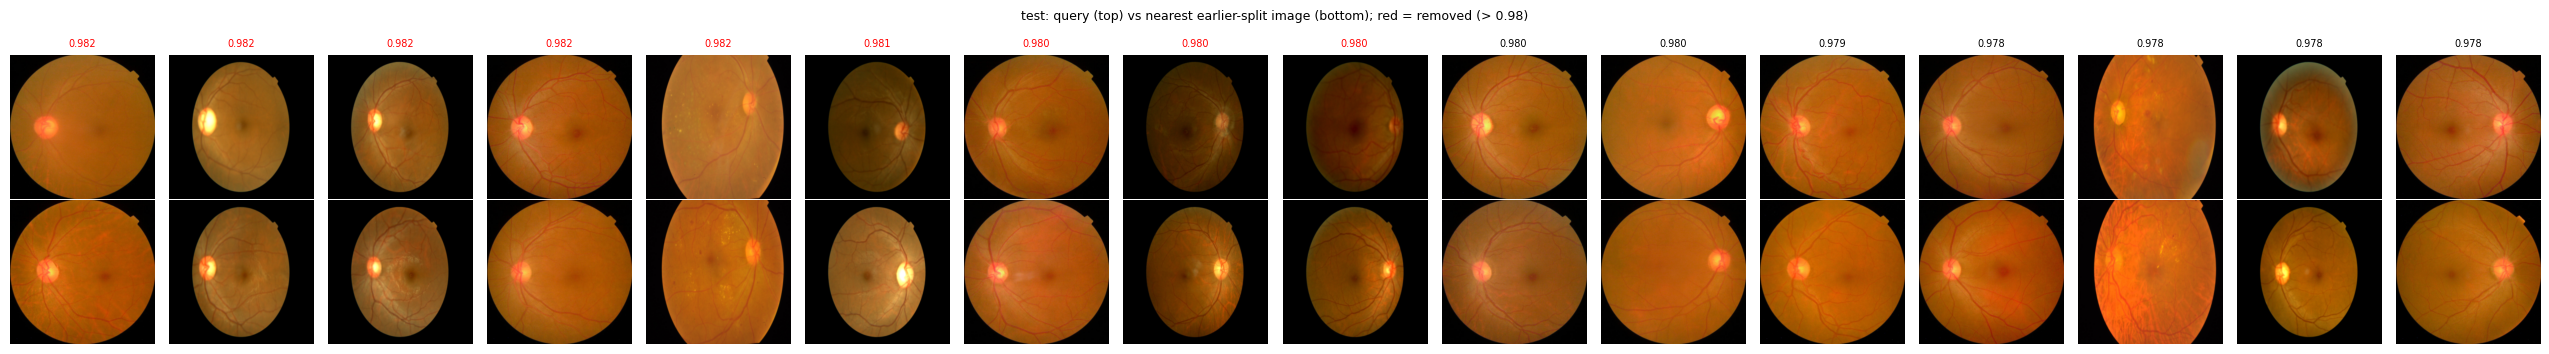

max cosine similarity to an earlier split (after mean-image removal):
  val: median=0.935 p99=1.000 max=1.000 | n>0.98: 35
  test: median=0.947 p99=1.000 max=1.000 | n>0.98: 54
removed near-duplicates from val/test: val 439->404, test 439->385 (list saved; train untouched)
If the counts above are large, inspect dedup_removed_fundus.csv and report them in the paper.


In [4]:
import matplotlib.pyplot as plt
# ---- near-duplicate audit: APTOS is known to contain duplicate images; duplicates across train/test inflate ID AUC ----
def tiny_vec(path):
    g = Image.fromarray(BANK[PATH2ROW[path]]).convert('L').resize((32, 32), Image.BILINEAR)
    return np.asarray(g, dtype=np.float32).ravel()

def _rownorm(V):                                   # invariant to global brightness/contrast shifts
    return (V - V.mean(1, keepdims=True)) / (V.std(1, keepdims=True) + 1e-6)
V_tr = _rownorm(np.stack([tiny_vec(p) for p in tr.path])); mean_img = V_tr.mean(0, keepdims=True)
def _prep(V):
    V = _rownorm(V) - mean_img                      # remove the shared 'average fundus' structure
    return V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-6)
Vtr_n = V_tr - mean_img; Vtr_n = Vtr_n / (np.linalg.norm(Vtr_n, axis=1, keepdims=True) + 1e-6)
Vva_n = _prep(np.stack([tiny_vec(p) for p in va.path]))
Vte_n = _prep(np.stack([tiny_vec(p) for p in te.path]))
sim_va = (Vva_n @ Vtr_n.T).max(1)
sim_te = (np.maximum((Vte_n @ Vtr_n.T).max(1), (Vte_n @ Vva_n.T).max(1)))
DUP_THR = 0.98
# --- sensitivity of the removal to the threshold + visual spot-check (look at dedup_pairs_*.png before trusting 0.98) ---
for t_ in (0.95, 0.97, 0.98, 0.99, 0.995):
    print(f'  threshold {t_}: val removed {(sim_va > t_).sum()}, test removed {(sim_te > t_).sum()}')
def _pair_fig(df_q, sims, Vq, refs, name, n=8):
    # show the n pairs closest to the threshold from each side (n above, n below), query image on top, its nearest earlier-split image below
    order = np.argsort(np.abs(sims - DUP_THR))[:2 * n]
    order = order[np.argsort(-sims[order])]
    refV, refdf = refs
    fig, axes = plt.subplots(2, len(order), figsize=(1.6 * len(order), 3.6))
    for j, i in enumerate(order):
        nn_ = int(np.argmax(Vq[i] @ refV.T))
        axes[0, j].imshow(BANK[PATH2ROW[df_q.iloc[i].path]]); axes[1, j].imshow(BANK[PATH2ROW[refdf.iloc[nn_].path]])
        axes[0, j].set_title(f'{sims[i]:.3f}', fontsize=7, color='r' if sims[i] > DUP_THR else 'k')
        for r_ in (0, 1): axes[r_, j].axis('off')
    plt.suptitle(f'{name}: query (top) vs nearest earlier-split image (bottom); red = removed (> {DUP_THR})', fontsize=9)
    plt.tight_layout(); plt.savefig(f'{RES}/dedup_pairs_{name}_{TAG}.png', dpi=130); plt.show()
try:
    _pair_fig(va, sim_va, Vva_n, (Vtr_n, tr), 'val')
    _pair_fig(te, sim_te, Vte_n, (Vtr_n, tr), 'test')
except Exception as e_:
    print('[dedup figure] failed (non-fatal):', e_)
print('max cosine similarity to an earlier split (after mean-image removal):')
for nm, s in [('val', sim_va), ('test', sim_te)]:
    print(f'  {nm}: median={np.median(s):.3f} p99={np.percentile(s, 99):.3f} max={s.max():.3f} | n>{DUP_THR}: {(s > DUP_THR).sum()}')
dup_rows = pd.concat([va[sim_va > DUP_THR].assign(sim=sim_va[sim_va > DUP_THR]),
                      te[sim_te > DUP_THR].assign(sim=sim_te[sim_te > DUP_THR])])
dup_rows[['id', 'source', 'sim']].to_csv(f'{RES}/dedup_removed_{TAG}.csv', index=False)
n0 = (len(va), len(te))
va, te = va[sim_va <= DUP_THR].reset_index(drop=True), te[sim_te <= DUP_THR].reset_index(drop=True)
print(f'removed near-duplicates from val/test: val {n0[0]}->{len(va)}, test {n0[1]}->{len(te)} (list saved; train untouched)')
print('If the counts above are large, inspect dedup_removed_fundus.csv and report them in the paper.')


## 2. Degradation features (BRISQUE, NIQE, PIQE, MUSIQ + 7 handcrafted), cached per split

In [5]:
all_df = pd.concat([tr, va, te, me], ignore_index=True)
all_df.to_csv(f'{FEAT}/frames.csv', index=False)
print('TOTAL images:', len(all_df))

import pyiqa
ALL_FEATS = ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'lum_mean', 'lum_std', 'colorfulness',
             'dark_channel', 'rms_contrast', 'dyn_range']

def _load_full(p):
    return Image.open(p).convert('RGB')

class DegradationExtractor:
    def __init__(self, device):
        self.device = device
        self.iqa = {m: pyiqa.create_metric(m, device=device) for m in ['brisque', 'niqe', 'piqe', 'musiq']}
    @staticmethod
    def _t(img, size=512):
        img = img.resize((size, size), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img)).permute(2, 0, 1).float() / 255.
    def handcrafted(self, img):
        a = np.asarray(img.resize((256, 256), Image.BICUBIC)).astype(np.float32) / 255.
        g = a.mean(axis=2)
        blur = float(ndimage.laplace(g).var())
        r, gg, b = a[..., 0], a[..., 1], a[..., 2]
        rg, yb = r - gg, 0.5 * (r + gg) - b
        colorfulness = float(np.sqrt(rg.std() ** 2 + yb.std() ** 2) + 0.3 * np.sqrt(rg.mean() ** 2 + yb.mean() ** 2))
        sw = np.lib.stride_tricks.sliding_window_view(g, (15, 15))
        dark = float(sw.min(axis=(-1, -2)).mean())
        return dict(blur=blur, lum_mean=float(g.mean()), lum_std=float(g.std()), colorfulness=colorfulness,
                    dark_channel=dark, rms_contrast=float(g.std()),
                    dyn_range=float(np.percentile(g, 99) - np.percentile(g, 1)))
    @torch.no_grad()
    def extract(self, df, batch=16):
        rows, paths = [], df['path'].tolist()
        with ThreadPoolExecutor(8) as pool:                       # threaded decoding of the full-res images
            for i in range(0, len(paths), batch):
                imgs = list(pool.map(_load_full, paths[i:i + batch]))
                t = torch.stack([self._t(im) for im in imgs]).to(self.device)
                sc = {m: self.iqa[m](t).flatten().cpu().numpy() for m in self.iqa}
                for j, im in enumerate(imgs):
                    row = {m: float(sc[m][j]) for m in sc}
                    row.update(self.handcrafted(im)); rows.append(row)
                if (i // batch) % 25 == 0:
                    print(f'  {min(i + batch, len(paths))}/{len(paths)}', end='\r')
        return pd.concat([df.reset_index(drop=True).copy(), pd.DataFrame(rows)], axis=1)

ext = DegradationExtractor(DEVICE)
feat_frames = []
for name, d in [('train', tr), ('val', va), ('test', te), ('external', me)]:
    cache = f'{FEAT}/{name}_degradation.csv'
    f = pd.read_csv(cache, dtype={'id': str, 'path': str, 'patient': str}) if os.path.exists(cache) else None
    ok = (f is not None and len(f) == len(d) and set(['id', 'source', 'label', 'grade', 'path'] + ALL_FEATS).issubset(f.columns)
          and not f['label'].isna().any() and f['id'].astype(str).tolist() == d['id'].astype(str).tolist())
    if ok:
        print(f'{name}: loaded cache ({len(f)} rows)')
    else:
        print(f'{name}: extracting {len(d)} images (cache missing/stale)...')
        f = ext.extract(d); f.to_csv(cache, index=False)
    feat_frames.append(f)
del ext; torch.cuda.empty_cache()
FD = pd.concat(feat_frames, ignore_index=True)
FD.to_csv(f'{FEAT}/all_degradation.csv', index=False)
print('features done:', FD.shape)

# drop features that are constant on the TRAIN split (e.g. colorfulness on grayscale chest X-rays)
_sd = FD.loc[FD.source == SRC_TR, ALL_FEATS].std()
FEATS = [f for f in ALL_FEATS if _sd[f] > 1e-6]
if len(FEATS) < len(ALL_FEATS):
    print('dropped constant-on-train degradation features:', [f for f in ALL_FEATS if f not in FEATS])
print('degradation features used (%d): %s' % (len(FEATS), FEATS))
assert not FD[FEATS].isna().any().any(), 'NaN in degradation features - inspect extraction.'


TOTAL images: 4585
Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 361kB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 15.0MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/musiq_koniq_ckpt-e95806b9.pth" to /root/.cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth



100%|██████████| 104M/104M [00:01<00:00, 68.9MB/s]


Loading pretrained model MUSIQ from /root/.cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth
train: extracting 2052 images (cache missing/stale)...
val: extracting 404 images (cache missing/stale)...
test: extracting 385 images (cache missing/stale)...
external: extracting 1744 images (cache missing/stale)...
features done: (4585, 16)
degradation features used (11): ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'lum_mean', 'lum_std', 'colorfulness', 'dark_channel', 'rms_contrast', 'dyn_range']


## 3. Figure 1 — degradation distributions and extremes

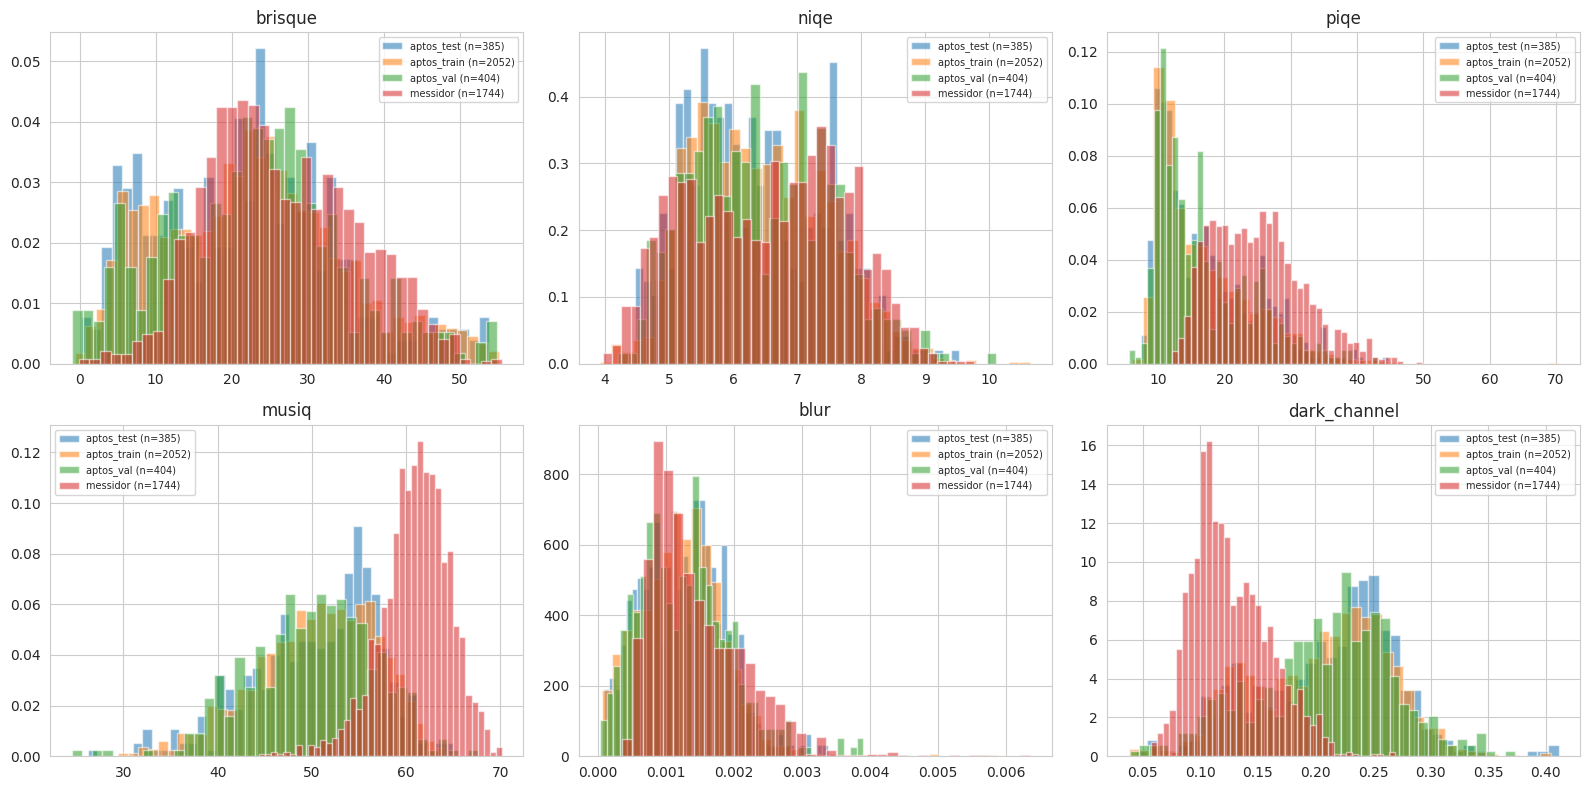

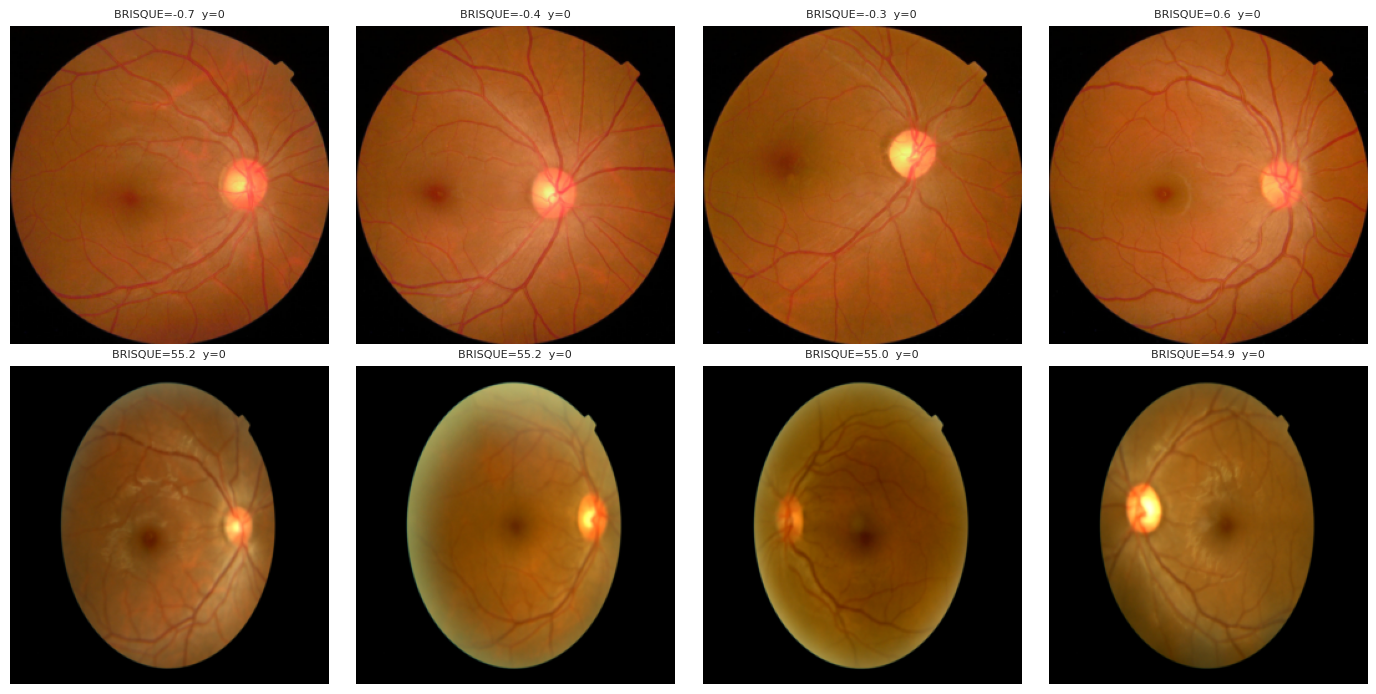

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, ft in zip(axes.ravel(), ['brisque', 'niqe', 'piqe', 'musiq', 'blur', 'dark_channel']):
    for src, d in FD.groupby('source'):
        ax.hist(d[ft], bins=40, alpha=0.55, label=f'{src} (n={len(d)})', density=True)
    ax.set_title(ft); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{RES}/fig1_degradation_distributions_{TAG}.png', dpi=200); plt.show()

tr_f = FD[FD.source == SRC_TR]
ex = pd.concat([tr_f.nsmallest(4, 'brisque'), tr_f.nlargest(4, 'brisque')])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, r) in zip(axes.ravel(), ex.iterrows()):
    ax.imshow(BANK[PATH2ROW[r['path']]]); ax.axis('off')
    ax.set_title(f"BRISQUE={r['brisque']:.1f}  y={int(r['label'])}", fontsize=8)
plt.tight_layout(); plt.savefig(f'{RES}/fig1b_extremes_{TAG}.png', dpi=200); plt.show()


## 4. Probe study (RQ1): is disease predictable from degradation alone?
Negative controls (10 repeats each) **must be ≈ 0.5**; table rows are now built from an explicit name→value list (the earlier version zipped two lists in different orders, which produced the 'impossible' 0.648 / 0.188 / 0.872 values).

=== probe diagnostics ===
FD source counts: {'aptos_train': 2052, 'messidor': 1744, 'aptos_val': 404, 'aptos_test': 385}
negative controls ~0.5 ? True (if False, STOP: the probe pipeline leaks)
                                                         probe  value     sd         note
                                APTOS-2019 5-fold AUC - LogReg 0.9023 0.0094             
                                   APTOS-2019 5-fold AUC - GBM 0.9413 0.0088             
  APTOS-2019 5-fold AUC - pyiqa-only (BRISQUE/NIQE/PIQE/MUSIQ) 0.8720 0.0181             
                      APTOS-2019 5-fold AUC - handcrafted-only 0.7585 0.0270             
                      NEG CONTROL per-column shuffle (10 reps) 0.4956 0.0174 must be ~0.5
                         NEG CONTROL per-row shuffle (10 reps) 0.5122 0.0149 must be ~0.5
Messidor-2 external AUC - LogReg (trained on APTOS-2019 train) 0.6479    NaN             
                                 Messidor-2 external AUC - GBM 0.6331    NaN          

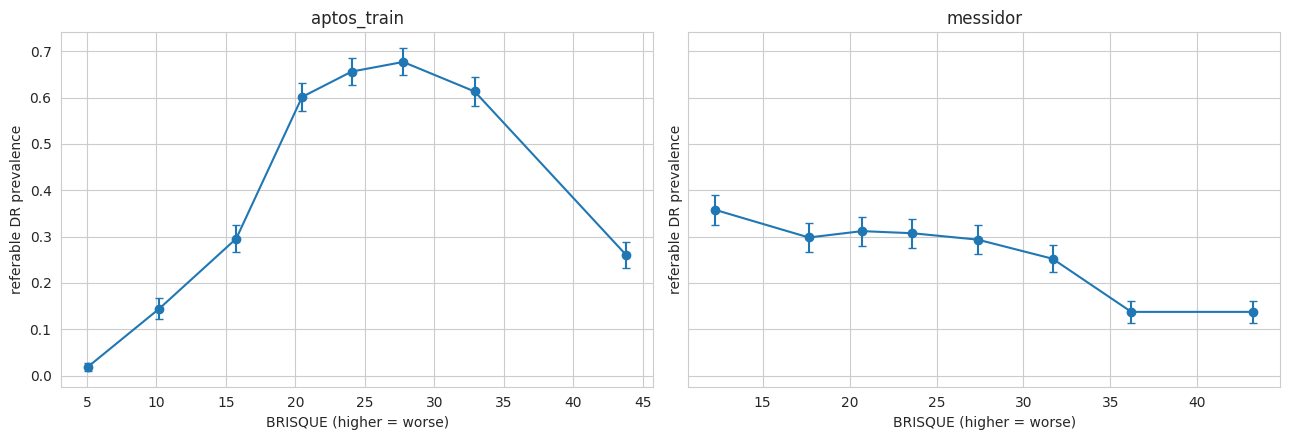

In [7]:
print('=== probe diagnostics ===')
print('FD source counts:', FD.source.value_counts().to_dict())
tr_mask = (FD.source.values == SRC_TR); ex_mask = (FD.source.values == SRC_EX)
va_mask = (FD.source.values == SRC_VA); te_mask = (FD.source.values == SRC_TE)
assert tr_mask.sum() > (50 if SMOKE else 500) and ex_mask.sum() > (50 if SMOKE else 100), 'too few train/external rows in FD.'
assert not np.isnan(FD.label.values).any()
ytr = FD.label.values[tr_mask].astype(int); yex = FD.label.values[ex_mask].astype(int)

# z-score with TRAIN statistics only
mu_tr, sd_tr = FD.loc[tr_mask, FEATS].mean(), FD.loc[tr_mask, FEATS].std().replace(0, 1)
X = ((FD[FEATS] - mu_tr) / sd_tr).values.astype(np.float64)

def cv_auc(Xm, y, model_fn, n_splits=5, seed=SEED):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    aucs = []
    for a, b in skf.split(Xm, y):
        m = model_fn(); m.fit(Xm[a], y[a])
        aucs.append(roc_auc_score(y[b], m.predict_proba(Xm[b])[:, 1]))
    return float(np.mean(aucs)), float(np.std(aucs))
LR = lambda: LogisticRegression(max_iter=3000)
GB = lambda: HistGradientBoostingClassifier(max_iter=300, random_state=SEED)

probe_rows = []
def add_probe(name, mean, sd=None, note=''):
    probe_rows.append({'probe': name, 'value': round(float(mean), 4), 'sd': (None if sd is None else round(float(sd), 4)), 'note': note})

# --- real probes (disease from degradation features ALONE) ---
add_probe(f'{NAME_ID} 5-fold AUC - LogReg', *cv_auc(X[tr_mask], ytr, LR))
add_probe(f'{NAME_ID} 5-fold AUC - GBM', *cv_auc(X[tr_mask], ytr, GB))
PYIQA_F = [f for f in ['brisque', 'niqe', 'piqe', 'musiq'] if f in FEATS]
HC_F = [f for f in FEATS if f not in PYIQA_F]
for nm, fl in [('pyiqa-only (BRISQUE/NIQE/PIQE/MUSIQ)', PYIQA_F), ('handcrafted-only', HC_F)]:
    ix = [FEATS.index(f) for f in fl]
    add_probe(f'{NAME_ID} 5-fold AUC - {nm}', *cv_auc(X[:, ix][tr_mask], ytr, LR))

# --- negative controls: 10 independent repeats each, must all be ~0.5 ---
col_aucs, row_aucs = [], []
for r in range(10):
    g = np.random.default_rng(1000 + r)
    Xc = X[tr_mask].copy()
    for j in range(Xc.shape[1]):
        Xc[:, j] = Xc[g.permutation(len(Xc)), j]                       # per-COLUMN shuffle
    col_aucs.append(cv_auc(Xc, ytr, LR, seed=r)[0])
    Xr = X[tr_mask][np.random.default_rng(2000 + r).permutation(int(tr_mask.sum()))]   # per-ROW shuffle
    row_aucs.append(cv_auc(Xr, ytr, LR, seed=r)[0])
add_probe('NEG CONTROL per-column shuffle (10 reps)', np.mean(col_aucs), np.std(col_aucs), 'must be ~0.5')
add_probe('NEG CONTROL per-row shuffle (10 reps)', np.mean(row_aucs), np.std(row_aucs), 'must be ~0.5')
ctrl_ok = abs(np.mean(col_aucs) - 0.5) < 0.04 and abs(np.mean(row_aucs) - 0.5) < 0.04
print('negative controls ~0.5 ?', ctrl_ok, '(if False, STOP: the probe pipeline leaks)')

# --- external transfer (probe trained on TRAIN only) ---
deg_lr = LogisticRegression(max_iter=3000).fit(X[tr_mask], ytr)
deg_gb = HistGradientBoostingClassifier(max_iter=300, random_state=SEED).fit(X[tr_mask], ytr)
add_probe(f'{NAME_EX} external AUC - LogReg (trained on {NAME_ID} train)', roc_auc_score(yex, deg_lr.predict_proba(X[ex_mask])[:, 1]))
add_probe(f'{NAME_EX} external AUC - GBM', roc_auc_score(yex, deg_gb.predict_proba(X[ex_mask])[:, 1]))
# sign-flip check on the headline degradation measure
add_probe(f'{NAME_EX} external AUC - BRISQUE alone (raw sign)', roc_auc_score(yex, FD.loc[ex_mask, 'brisque']))
add_probe(f'{NAME_ID} train AUC - BRISQUE alone (raw sign)', roc_auc_score(ytr, FD.loc[tr_mask, 'brisque']))

# degradation-only classifier scores (used later as the "deg_only" reference arm)
DEG_SCORE = {'va': deg_lr.predict_proba(X[va_mask])[:, 1], 'te': deg_lr.predict_proba(X[te_mask])[:, 1],
             'ex': deg_lr.predict_proba(X[ex_mask])[:, 1]}

def save_probe_table():
    pt = pd.DataFrame(probe_rows); pt.to_csv(f'{RES}/table1_probe_{TAG}.csv', index=False)
    return pt
print(save_probe_table().to_string(index=False))

# --- univariate association per feature: does the SIGN / strength transfer? ---
uni = []
for f in FEATS:
    uni.append({'feature': f, f'AUC_{SRC_TR}': roc_auc_score(ytr, FD.loc[tr_mask, f]),
                f'AUC_{SRC_EX}': roc_auc_score(yex, FD.loc[ex_mask, f])})
uni = pd.DataFrame(uni)
uni['sign_flip'] = (uni.iloc[:, 1] - 0.5) * (uni.iloc[:, 2] - 0.5) < 0
print(uni.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
uni.to_csv(f'{RES}/table1b_univariate_{TAG}.csv', index=False)

# --- mechanism figure: prevalence vs BRISQUE ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, src in zip(axes, [SRC_TR, SRC_EX]):
    d = FD[FD.source == src].copy()
    d['bin'] = pd.qcut(d['brisque'], 8, duplicates='drop')
    g = d.groupby('bin', observed=True).agg(prev=('label', 'mean'), n=('label', 'size'), brisque=('brisque', 'mean'))
    ax.errorbar(g['brisque'], g['prev'], yerr=np.sqrt(np.clip(g['prev'] * (1 - g['prev']) / g['n'], 0, None)), marker='o', capsize=3)
    ax.set_title(src); ax.set_xlabel('BRISQUE (higher = worse)'); ax.set_ylabel(f'{TASK} prevalence')
plt.tight_layout(); plt.savefig(f'{RES}/fig2_prevalence_vs_degradation_{TAG}.png', dpi=200); plt.show()


In [8]:
# --- fundus-only: 5-grade ordinal probe (quadratic-weighted kappa) on Messidor-2 ---
gtr = FD.grade.values[tr_mask].astype(int)
gb5 = HistGradientBoostingClassifier(max_iter=300, random_state=SEED).fit(X[tr_mask], gtr)
add_probe(f'{NAME_EX} 5-grade QWK (GBM trained on {NAME_ID}, degradation only)',
          cohen_kappa_score(FD.grade.values[ex_mask].astype(int), gb5.predict(X[ex_mask]), weights='quadratic'))
print(save_probe_table().tail(1).to_string(index=False))


                                                               probe  value  sd note
Messidor-2 5-grade QWK (GBM trained on APTOS-2019, degradation only) 0.1876 NaN     


## 5. Models — six backbones × arms × seeds (full-model checkpoints, speed benchmark first, seed-major order, time-budget guard)

In [9]:
# ---------------- degradation buckets + normalisation constants: TRAIN split only ----------------
qs = np.quantile(FD.loc[tr_mask, 'brisque'], np.linspace(0, 1, 6))
FD['deg_bucket'] = np.clip(np.digitize(FD['brisque'], qs[1:-1]), 0, 4).astype(int)
deg_z_mu = FD.loc[tr_mask, FEATS].mean().values.astype(np.float32)
deg_z_sd = FD.loc[tr_mask, FEATS].std().replace(0, 1).values.astype(np.float32)

import timm
BB = BACKBONES[0]                      # current backbone (global; every loop below sets it)
FEAT_DIM, NORM, train_tf, eval_tf, aug_train_tf, aug_strong_tf = None, None, None, None, None, None

class RandomGamma:
    def __init__(self, lo=0.65, hi=1.5): self.lo, self.hi = lo, hi
    def __call__(self, img):
        a = np.asarray(img).astype(np.float32) / 255.
        g = math.exp(random.uniform(math.log(self.lo), math.log(self.hi)))
        return Image.fromarray((np.power(a, g) * 255).astype(np.uint8))
class RandomNoise:
    def __init__(self, lo=2, hi=12, p=1.0): self.lo, self.hi, self.p = lo, hi, p
    def __call__(self, img):
        if random.random() > self.p: return img
        a = np.asarray(img).astype(np.float32)
        a += np.random.normal(0, random.uniform(self.lo, self.hi), a.shape)
        return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
class RandomBlur:
    def __init__(self, lo=0.5, hi=2.0, p=1.0): self.lo, self.hi, self.p = lo, hi, p
    def __call__(self, img):
        if random.random() > self.p: return img
        return img.filter(ImageFilter.GaussianBlur(random.uniform(self.lo, self.hi)))
class RandomContrast:
    def __init__(self, lo=0.6, hi=1.4): self.lo, self.hi = lo, hi
    def __call__(self, img):
        return ImageEnhance.Contrast(img).enhance(random.uniform(self.lo, self.hi))
def set_backbone(name):
    """Switch the global backbone: feature dim and the normalisation constants come from the model's own pretrained config
    (e.g. the ViT checkpoint expects mean=std=0.5, ImageNet CNNs expect the ImageNet statistics)."""
    global BB, FEAT_DIM, NORM, train_tf, eval_tf, aug_train_tf, aug_strong_tf
    BB = name
    m = timm.create_model(name, pretrained=False, num_classes=0)
    FEAT_DIM = int(m.num_features); cfg = m.pretrained_cfg; del m
    NORM = T.Normalize(list(cfg['mean']), list(cfg['std']))
    train_tf = T.Compose([T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])
    eval_tf = T.Compose([T.CenterCrop(224), T.ToTensor(), NORM])
    aug_strong_tf = T.Compose([RandomGamma(), RandomContrast(), RandomBlur(), RandomNoise(),
                               T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])
    aug_train_tf = T.Compose([RandomGamma(0.8, 1.25), RandomContrast(0.8, 1.2), RandomBlur(0.3, 0.7, p=0.3), RandomNoise(1, 4, p=0.3),
                              T.RandomCrop(224), T.RandomHorizontalFlip(), T.ToTensor(), NORM])
    print(f'[backbone] {name}: feat_dim={FEAT_DIM} mean={tuple(round(x,3) for x in cfg["mean"])} std={tuple(round(x,3) for x in cfg["std"])}')

class DS(torch.utils.data.Dataset):
    """Reads pixels from the in-RAM BANK. deg_perm (optional) = fixed permutation used ONLY by harness_ctrl:
    the image at row i is paired with the degradation vector of row perm[i] (breaks the image<->degradation link)."""
    def __init__(self, df, tf, deg_perm=None):
        df = df.reset_index(drop=True)
        self.rows = np.array([PATH2ROW[p] for p in df['path']]); self.y = df['label'].values.astype(np.int64)
        if all(f in df.columns for f in FEATS):
            D = (df[FEATS].values.astype(np.float32) - deg_z_mu) / deg_z_sd
        else:
            D = np.zeros((len(df), len(FEATS)), np.float32)           # frames without features (audit set; baseline only)
        self.deg = torch.from_numpy(D.astype(np.float32))
        self.bkt = df['deg_bucket'].values.astype(np.int64) if 'deg_bucket' in df.columns else np.zeros(len(df), np.int64)
        self.tf, self.perm = tf, deg_perm
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        img = self.tf(Image.fromarray(BANK[self.rows[i]]))
        j = int(self.perm[i]) if self.perm is not None else i
        return img, self.y[i], self.deg[j], self.bkt[i]

class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam; return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        return -ctx.lam * g, None

def make_model(mode, pretrained=True):
    bb = timm.create_model(BB, pretrained=pretrained, num_classes=0).to(DEVICE)
    D, FD_ = len(FEATS), FEAT_DIM; ph = None
    if mode in ('baseline', 'aug', 'aug_strong'):
        head = nn.Linear(FD_, 2).to(DEVICE); extra = [head]
        def fwd(x, deg=None):
            f = bb(x); return head(f), f
    elif mode in ('harness', 'harness_ctrl'):
        dml = nn.Sequential(nn.Linear(D, 64), nn.ReLU(), nn.Linear(64, 32)).to(DEVICE)
        head = nn.Linear(FD_ + 32, 2).to(DEVICE); extra = [dml, head]
        def fwd(x, deg=None):
            f = bb(x); d = dml(deg)
            return head(torch.cat([f, d], 1)), f
    elif mode == 'harness_brisque':
        mask = torch.zeros(D, device=DEVICE); mask[FEATS.index('brisque')] = 1.0         # only BRISQUE reaches the degradation MLP
        dml = nn.Sequential(nn.Linear(D, 64), nn.ReLU(), nn.Linear(64, 32)).to(DEVICE)
        head = nn.Linear(FD_ + 32, 2).to(DEVICE); extra = [dml, head]
        def fwd(x, deg=None):
            f = bb(x); d = dml(deg * mask)
            return head(torch.cat([f, d], 1)), f
    elif mode == 'suppress':
        head = nn.Linear(FD_, 2).to(DEVICE)
        ph = nn.Sequential(nn.Linear(FD_, 256), nn.ReLU(), nn.Linear(256, 5)).to(DEVICE); extra = [head, ph]
        def fwd(x, deg=None):
            f = bb(x); return head(f), f
    else:
        raise ValueError(mode)
    return bb, fwd, extra, ph

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def _loader(ds, bs, shuffle, drop_last=False, persistent=True):
    return torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=N_WORKERS, pin_memory=True,
                                       drop_last=drop_last, persistent_workers=persistent and N_WORKERS > 0)

CKPT_FMT = 3        # {'fmt','bb','extra','val_auc'}: backbone AND all heads (the old backbone-only format is rejected)
def ckpt_path(mode, seed, bb=None): return f'{CKPT}/{bb or BB}_{mode}_s{seed}.pt'
def ckpt_valid(path):
    if not os.path.exists(path): return None
    try:
        c = torch.load(path, map_location='cpu')
        return c if isinstance(c, dict) and c.get('fmt') == CKPT_FMT and 'extra' in c else None
    except Exception:
        return None

def train_arm(mode, seed, epochs=EPOCHS, bs=BS, lr_head=1e-3):
    set_seed(seed); lr_bb = LR_BB[BB]
    dtr_, dva_ = FD[FD.source == SRC_TR].reset_index(drop=True), FD[FD.source == SRC_VA].reset_index(drop=True)
    perm_tr = np.random.default_rng(seed).permutation(len(dtr_)) if mode == 'harness_ctrl' else None
    perm_va = np.random.default_rng(seed + 1).permutation(len(dva_)) if mode == 'harness_ctrl' else None
    tf_tr = {'aug': aug_train_tf, 'aug_strong': aug_strong_tf}.get(mode, train_tf)
    tr_ld = _loader(DS(dtr_, tf_tr, perm_tr), bs, True, drop_last=True)
    va_ld = _loader(DS(dva_, eval_tf, perm_va), 64, False)
    bb, fwd, extra, ph = make_model(mode)
    opt = torch.optim.AdamW([{'params': bb.parameters(), 'lr': lr_bb}] + [{'params': m.parameters(), 'lr': lr_head} for m in extra],
                            weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    n_pos = int(dtr_.label.sum()); n_neg = len(dtr_) - n_pos
    ce = nn.CrossEntropyLoss(weight=torch.tensor([1.0, n_neg / max(1, n_pos)], device=DEVICE))
    best_auc, best_state, best_ep, best_key = -1.0, None, -1, None
    best_adv, n_iter_tot, it_done = float('nan'), epochs * len(tr_ld), 0
    for ep in range(epochs):
        bb.train(); [m.train() for m in extra]; t0 = time.time(); tot = 0.0; adv_hit = 0.0; nb = 0
        for img, y, deg, bkt in tr_ld:
            img, y, deg, bkt = img.to(DEVICE, non_blocking=True), y.to(DEVICE), deg.to(DEVICE).float(), bkt.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', enabled=AMP):
                logits, f = fwd(img, deg)
                loss = ce(logits.float(), y)
                if mode == 'suppress':
                    p_ = it_done / max(1, n_iter_tot)                          # DANN ramp: lambda 0 -> LAM (adversary learns first, then pushes)
                    lam_t = LAM * (2.0 / (1.0 + math.exp(-10.0 * p_)) - 1.0)
                    adv_logits = ph(GRL.apply(f, lam_t)).float()
                    loss = loss + ADV_W * TF.cross_entropy(adv_logits, bkt)
                    adv_hit += (adv_logits.argmax(1) == bkt).float().mean().item()
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1; it_done += 1
        sched.step()
        bb.eval(); [m.eval() for m in extra]; ps, ys = [], []; vadv_hit, vadv_n = 0.0, 0
        with torch.no_grad(), torch.autocast(device_type='cuda', enabled=AMP):
            for img, y, deg, bkt in va_ld:
                logits, f_ = fwd(img.to(DEVICE), deg.to(DEVICE).float())
                ps.append(logits.float().softmax(1)[:, 1].cpu()); ys.append(y)
                if mode == 'suppress':
                    vadv_hit += (ph(f_).argmax(1).cpu() == bkt).float().sum().item(); vadv_n += len(bkt)
        vauc = roc_auc_score(torch.cat(ys).numpy(), torch.cat(ps).numpy())
        vadv = vadv_hit / max(1, vadv_n) if mode == 'suppress' else float('nan')
        # checkpoint selection: best val AUC; for `suppress` only among epochs whose HELD-OUT adversary accuracy is near chance (0.2)
        elig = (abs(vadv - 0.2) <= ADV_TOL) if mode == 'suppress' else True
        key = (bool(elig), vauc)
        if best_key is None or key > best_key:
            best_key, best_adv = key, vadv
            best_auc, best_ep = vauc, ep + 1
            best_state = {'fmt': CKPT_FMT, 'backbone': BB, 'mode': mode, 'seed': seed, 'val_auc': float(vauc), 'epoch': ep + 1,
                          'adv_val_acc': float(vadv), 'adv_ok': bool(elig),
                          'bb': {k: v.detach().cpu().clone() for k, v in bb.state_dict().items()},
                          'extra': [{k: v.detach().cpu().clone() for k, v in m.state_dict().items()} for m in extra]}
        print(f'  [{BB}|{mode}|s{seed}] ep{ep+1}/{epochs} loss={tot/max(nb,1):.4f} val_auc={vauc:.4f} best={best_auc:.4f}'
              + (f' adv_train={adv_hit/max(nb,1):.3f} adv_val={vadv:.3f}(chance .2){"" if elig else " [not eligible]"}' if mode == 'suppress' else '') + f' ({time.time()-t0:.0f}s)')
    torch.save(best_state, ckpt_path(mode, seed))
    del bb, fwd, extra, ph, opt; torch.cuda.empty_cache()
    return best_auc, best_ep, best_adv, bool(best_key[0])

# ---------------- speed benchmark: projects the full grid BEFORE launching it ----------------
def benchmark(n_iter=12):
    rows = []
    n_train = int((FD.source == SRC_TR).sum()); it_ep = n_train // BS
    for b in BACKBONES:
        set_backbone(b)
        try:
            bb, fwd, extra, ph = make_model('suppress', pretrained=False)
            opt = torch.optim.AdamW(list(bb.parameters()) + [p for m in extra for p in m.parameters()], lr=1e-5)
            scaler = torch.cuda.amp.GradScaler(enabled=AMP)
            x = torch.randn(BS, 3, 224, 224, device=DEVICE); y = torch.randint(0, 2, (BS,), device=DEVICE)
            dg = torch.randn(BS, len(FEATS), device=DEVICE); bk = torch.randint(0, 5, (BS,), device=DEVICE)
            for i in range(n_iter + 3):
                if i == 3:
                    if DEVICE == 'cuda': torch.cuda.synchronize()
                    t = time.time()
                with torch.autocast(device_type='cuda', enabled=AMP):
                    lg, f = fwd(x, dg); loss = TF.cross_entropy(lg.float(), y) + TF.cross_entropy(ph(GRL.apply(f, LAM)).float(), bk)
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if DEVICE == 'cuda': torch.cuda.synchronize()
            sec_it = (time.time() - t) / n_iter
            n_runs = len(ARMS_FOR[b]) * len(SEEDS)
            h = sec_it * it_ep * EPOCHS * 1.15 * n_runs / 3600          # +15 % for validation passes
            rows.append({'backbone': b, 'params_M': sum(p.numel() for p in bb.parameters()) / 1e6, 'feat_dim': FEAT_DIM,
                         'sec_per_iter': round(sec_it, 3), 'runs': n_runs, 'projected_h': round(h, 2)})
            del bb, fwd, extra, ph, opt; torch.cuda.empty_cache()
        except Exception as e:
            rows.append({'backbone': b, 'error': str(e)[:120]})
    bt = pd.DataFrame(rows); print(bt.to_string(index=False))
    tot = bt['projected_h'].sum() if 'projected_h' in bt else float('nan')
    print(f'PROJECTED TRAINING TIME for the full grid (GPU compute only, data loading assumed hidden): {tot:.1f} h  '
          f'(budget {TIME_BUDGET_H} h).  If this is above the budget, split BACKBONES over two sessions.')
    bt.to_csv(f'{RES}/benchmark_{TAG}.csv', index=False); return bt
bench = benchmark()

# ---------------- training driver: seed-major, then backbone, then arm ----------------
# If the time budget runs out, every backbone already has the complete set of earlier seeds.
val_rows = []
for seed in SEEDS:
    for b in BACKBONES:
        set_backbone(b)
        for mode in ARMS_FOR[b]:
            c = ckpt_valid(ckpt_path(mode, seed))
            if c is not None:
                print(f'skip {b}|{mode}|seed {seed}: valid checkpoint exists (val_auc={c["val_auc"]:.4f})')
                val_rows.append({'backbone': b, 'arm': mode, 'seed': seed, 'val_auc': c['val_auc'], 'best_epoch': c['epoch'],
                                 'adv_val_acc': c.get('adv_val_acc', np.nan), 'adv_ok': c.get('adv_ok', True)}); continue
            if (time.time() - T0) / 3600 > TIME_BUDGET_H:
                print(f'TIME BUDGET reached ({TIME_BUDGET_H} h): not launching {b}|{mode}|seed {seed}'); continue
            print(f'=== training {b} | {mode} | seed {seed} === (elapsed {(time.time()-T0)/3600:.2f} h)')
            va_auc, be, adv_v, adv_ok = train_arm(mode, seed)
            val_rows.append({'backbone': b, 'arm': mode, 'seed': seed, 'val_auc': va_auc, 'best_epoch': be, 'adv_val_acc': adv_v, 'adv_ok': adv_ok})
va_df = pd.DataFrame(val_rows)
print(va_df.groupby(['backbone', 'arm']).val_auc.agg(['mean', 'std', 'count']).round(4))
if (va_df.arm == 'suppress').any():
    print('suppress adversary (held-out val accuracy at the selected epoch; chance = 0.20):')
    print(va_df[va_df.arm == 'suppress'][['backbone', 'seed', 'val_auc', 'best_epoch', 'adv_val_acc', 'adv_ok']].round(3).to_string(index=False))
va_df.to_csv(f'{RES}/val_aucs_{TAG}.csv', index=False)


[backbone] resnet50: feat_dim=2048 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[backbone] convnext_tiny: feat_dim=768 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[backbone] vit_small_patch16_224: feat_dim=384 mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)
[backbone] densenet121: feat_dim=1024 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[backbone] efficientnet_b0: feat_dim=1280 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
[backbone] swin_tiny_patch4_window7_224: feat_dim=768 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
                    backbone  params_M  feat_dim  sec_per_iter  runs  projected_h
                    resnet50 23.508032      2048         0.126    35         1.36
               convnext_tiny 27.820128       768         0.152    20         0.93
       vit_small_patch16_224 21.665664       384         0.101    20         0.62
                 densenet121  6.953856      1024         0.151    20         0.92
             efficientnet_b0 

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  [resnet50|baseline|s42] ep1/15 loss=0.5327 val_auc=0.9359 best=0.9359 (11s)
  [resnet50|baseline|s42] ep2/15 loss=0.3300 val_auc=0.9582 best=0.9582 (9s)
  [resnet50|baseline|s42] ep3/15 loss=0.2657 val_auc=0.9687 best=0.9687 (9s)
  [resnet50|baseline|s42] ep4/15 loss=0.2450 val_auc=0.9703 best=0.9703 (9s)
  [resnet50|baseline|s42] ep5/15 loss=0.2168 val_auc=0.9726 best=0.9726 (9s)
  [resnet50|baseline|s42] ep6/15 loss=0.2037 val_auc=0.9757 best=0.9757 (9s)
  [resnet50|baseline|s42] ep7/15 loss=0.1950 val_auc=0.9777 best=0.9777 (9s)
  [resnet50|baseline|s42] ep8/15 loss=0.1883 val_auc=0.9784 best=0.9784 (9s)
  [resnet50|baseline|s42] ep9/15 loss=0.1864 val_auc=0.9792 best=0.9792 (9s)
  [resnet50|baseline|s42] ep10/15 loss=0.1655 val_auc=0.9790 best=0.9792 (9s)
  [resnet50|baseline|s42] ep11/15 loss=0.1838 val_auc=0.9786 best=0.9792 (9s)
  [resnet50|baseline|s42] ep12/15 loss=0.1706 val_auc=0.9795 best=0.9795 (9s)
  [resnet50|baseline|s42] ep13/15 loss=0.1669 val_auc=0.9793 best=0.9795

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

... (9 outputs left out)

  [efficientnet_b0|baseline|s42] ep1/15 loss=0.2911 val_auc=0.9794 best=0.9794 (17s)
  [efficientnet_b0|baseline|s42] ep2/15 loss=0.1439 val_auc=0.9812 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep3/15 loss=0.1164 val_auc=0.9801 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep4/15 loss=0.0781 val_auc=0.9798 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep5/15 loss=0.0471 val_auc=0.9790 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep6/15 loss=0.0324 val_auc=0.9755 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep7/15 loss=0.0233 val_auc=0.9780 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep8/15 loss=0.0197 val_auc=0.9731 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep9/15 loss=0.0183 val_auc=0.9749 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep10/15 loss=0.0180 val_auc=0.9756 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep11/15 loss=0.0101 val_auc=0.9742 best=0.9812 (6s)
  [efficientnet_b0|baseline|s42] ep12/15 loss=0.0118 val_auc=0.9739 best=

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

  [swin_tiny_patch4_window7_224|baseline|s42] ep1/15 loss=0.2587 val_auc=0.9892 best=0.9892 (14s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep2/15 loss=0.1727 val_auc=0.9867 best=0.9892 (14s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep3/15 loss=0.1492 val_auc=0.9917 best=0.9917 (14s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep4/15 loss=0.1419 val_auc=0.9888 best=0.9917 (14s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep5/15 loss=0.1319 val_auc=0.9859 best=0.9917 (14s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep6/15 loss=0.1110 val_auc=0.9882 best=0.9917 (14s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep7/15 loss=0.1003 val_auc=0.9865 best=0.9917 (14s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep8/15 loss=0.0954 val_auc=0.9833 best=0.9917 (13s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep9/15 loss=0.0835 val_auc=0.9858 best=0.9917 (14s)
  [swin_tiny_patch4_window7_224|baseline|s42] ep10/15 loss=0.0736 val_auc=0.9863 best=0.9917 (14s)
  [swin_tiny_patch4

## 6. Evaluation (one loop over the backbones)
inference + checkpoint round-trip guard · tables · forensic probes · figures; every file is tagged `<TAG>_<backbone>`

[backbone] resnet50: feat_dim=2048 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING resnet50 ==============================
[resnet50] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [resnet50] per-seed AUCs ---
            arm  seed  id_test  external
       baseline    42    0.972     0.706
       baseline     7    0.972     0.677
       baseline  2024    0.971     0.680
       baseline    11    0.971     0.691
       baseline    99    0.972     0.701
        harness    42    0.968     0.737
        harness     7    0.966     0.724
        harness  2024    0.966     0.700
        harness    11    0.967     0.720
        harness    99    0.969     0.699
   harness_ctrl    42    0.972     0.682
   harness_ctrl     7    0.971     0.699
   harness_ctrl  2024    0.972     0.676
   harness_ctrl    11    0.974     0.698
   harness_ctrl    99    0.972     0.667
       suppress    42    0.966     0.688
       suppress     7

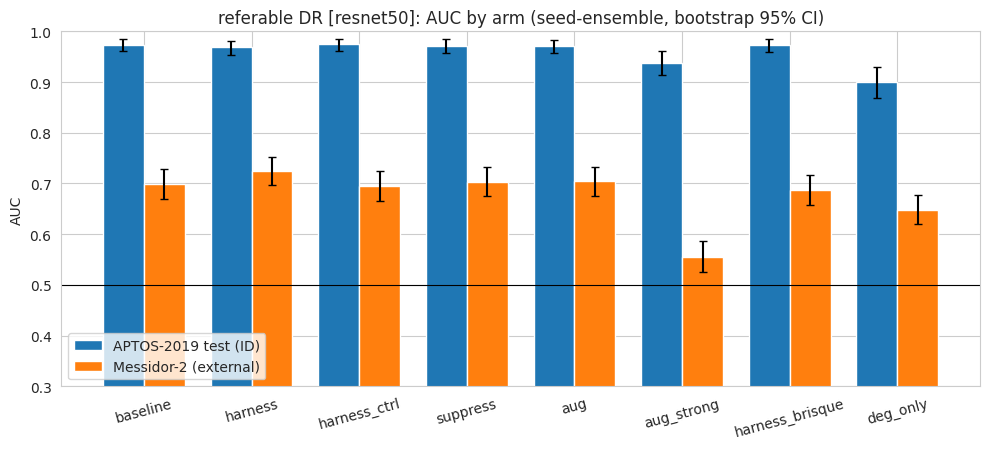

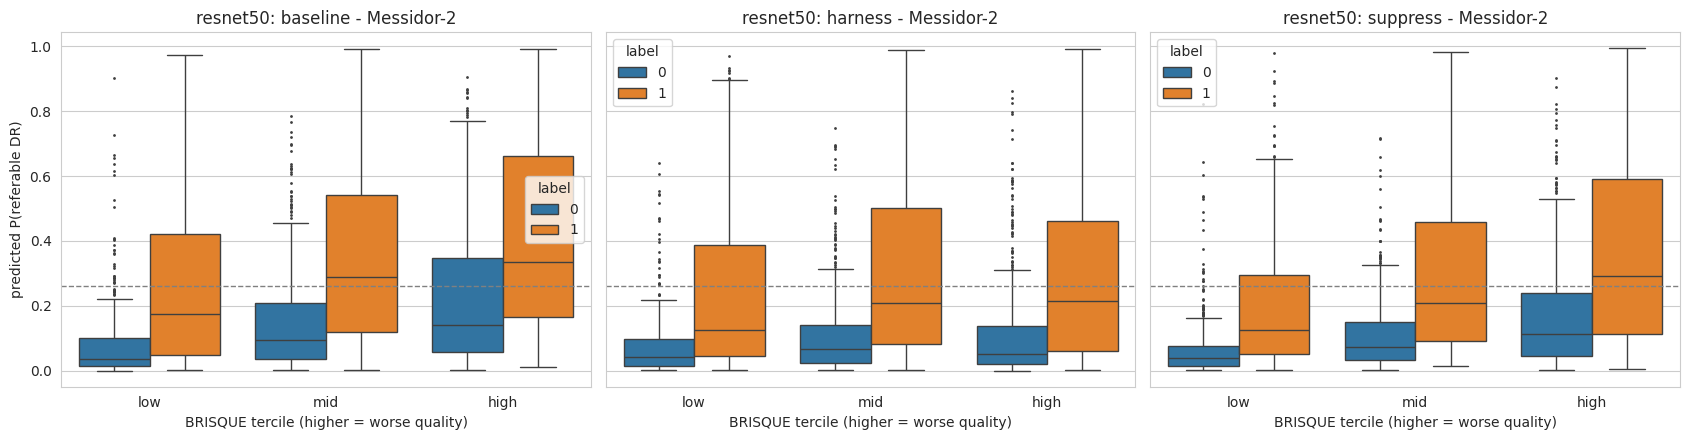

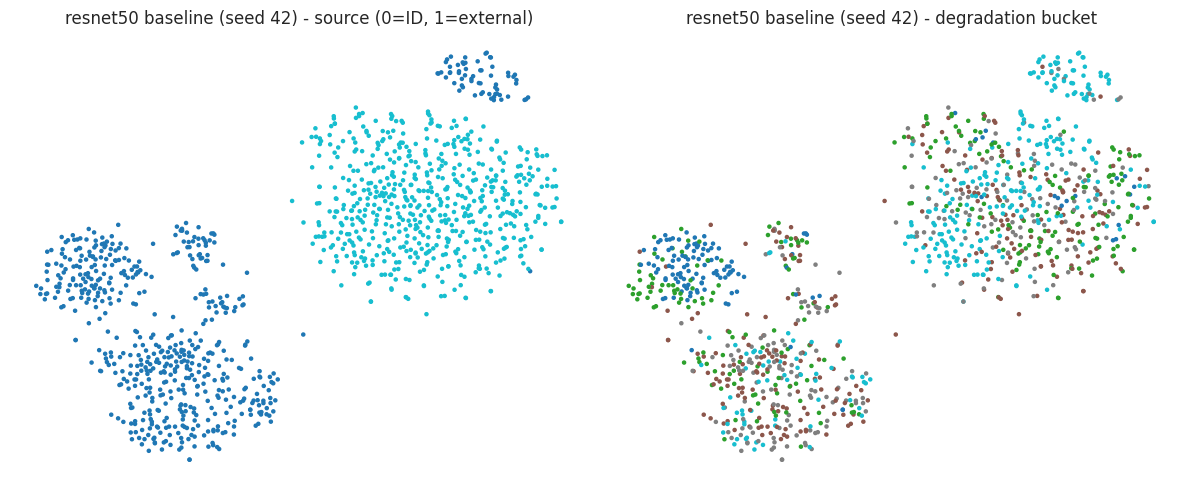

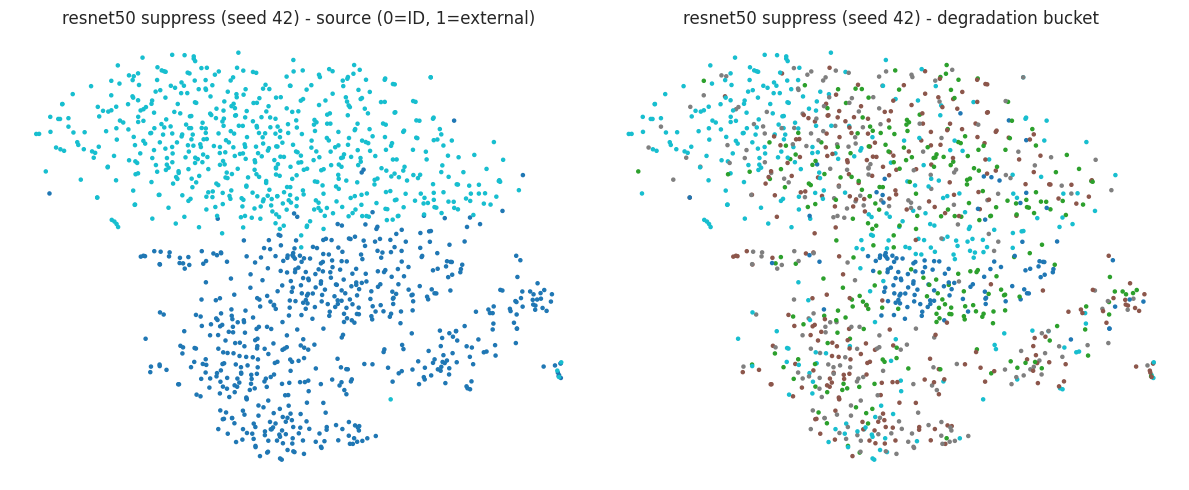

[backbone] convnext_tiny: feat_dim=768 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING convnext_tiny ==============================
[convnext_tiny] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [convnext_tiny] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.976     0.813
    baseline     7    0.980     0.786
    baseline  2024    0.981     0.821
    baseline    11    0.977     0.820
    baseline    99    0.978     0.840
     harness    42    0.974     0.776
     harness     7    0.977     0.821
     harness  2024    0.975     0.825
     harness    11    0.974     0.812
     harness    99    0.975     0.806
harness_ctrl    42    0.979     0.820
harness_ctrl     7    0.977     0.818
harness_ctrl  2024    0.978     0.779
harness_ctrl    11    0.977     0.826
harness_ctrl    99    0.979     0.800
    suppress    42    0.978     0.811
    suppress     7    0.976     0.795
    suppress  2

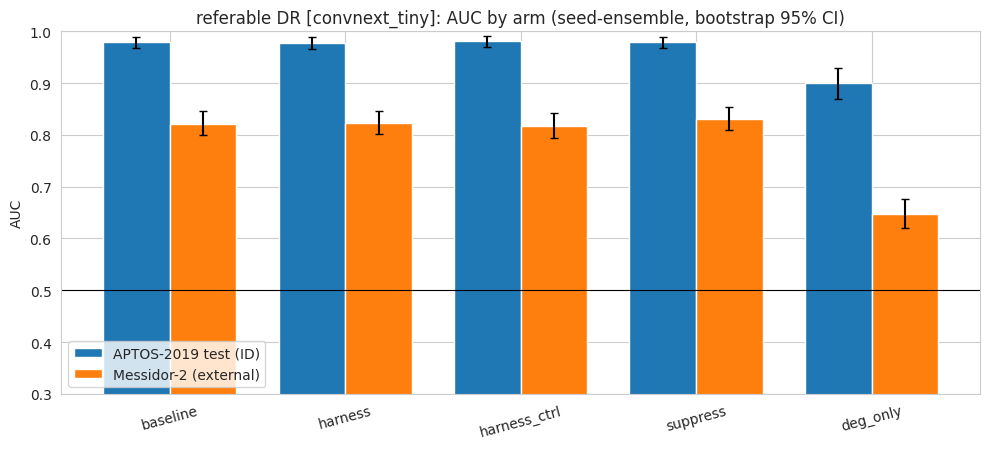

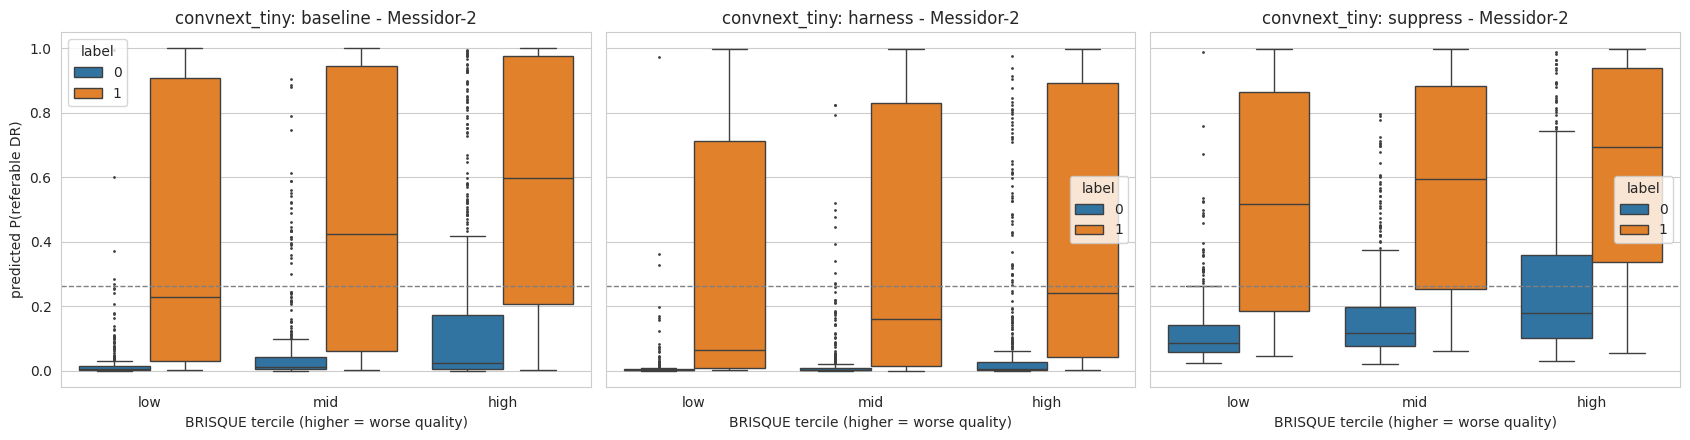

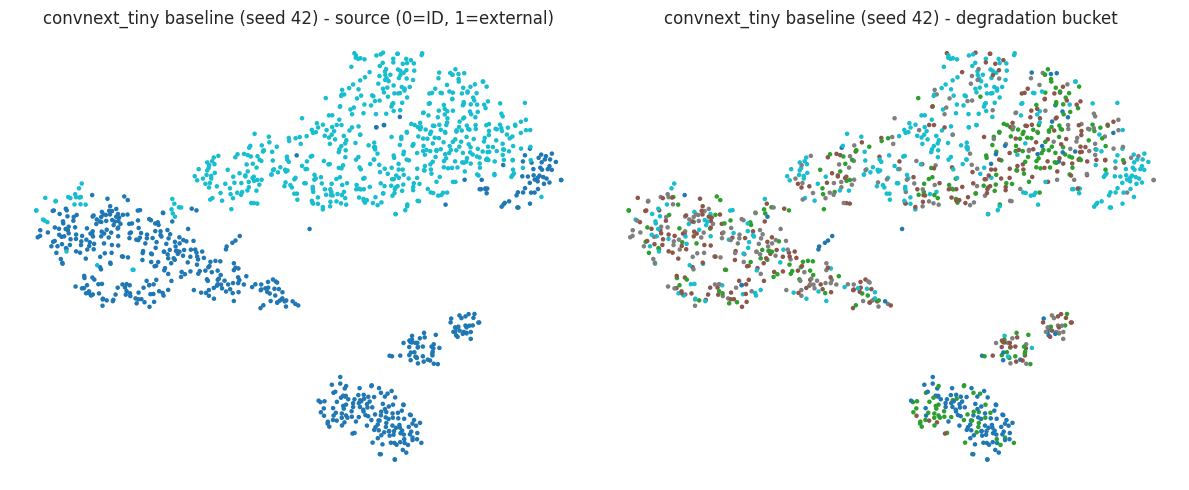

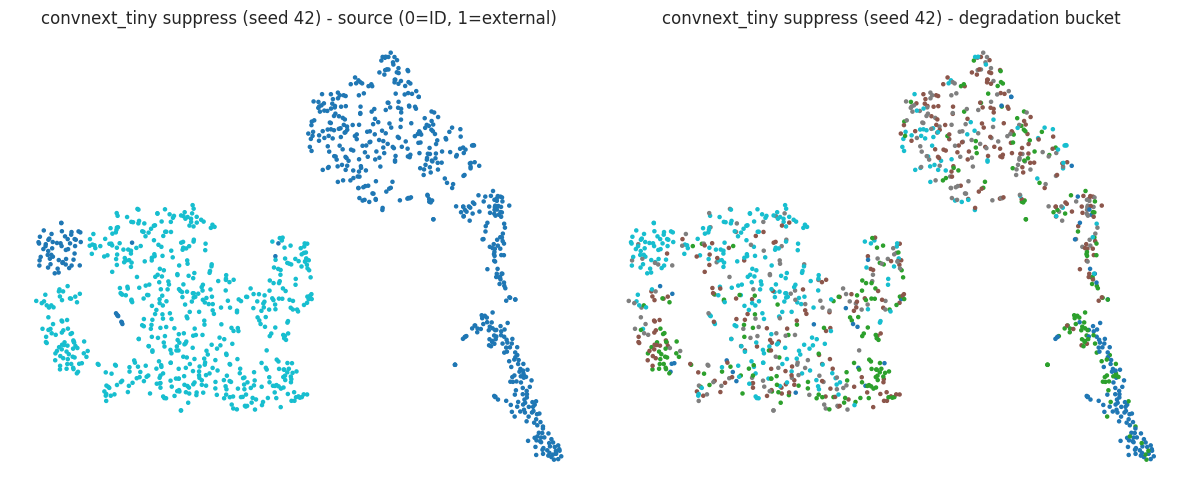

[backbone] vit_small_patch16_224: feat_dim=384 mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5)

============================== EVALUATING vit_small_patch16_224 ==============================
[vit_small_patch16_224] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [vit_small_patch16_224] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.984     0.728
    baseline     7    0.982     0.688
    baseline  2024    0.982     0.700
    baseline    11    0.983     0.673
    baseline    99    0.983     0.738
     harness    42    0.979     0.725
     harness     7    0.980     0.718
     harness  2024    0.980     0.708
     harness    11    0.982     0.703
     harness    99    0.981     0.729
harness_ctrl    42    0.980     0.714
harness_ctrl     7    0.983     0.707
harness_ctrl  2024    0.981     0.709
harness_ctrl    11    0.983     0.690
harness_ctrl    99    0.984     0.730
    suppress    42    0.977     0.748
    suppress     7    0.979     0

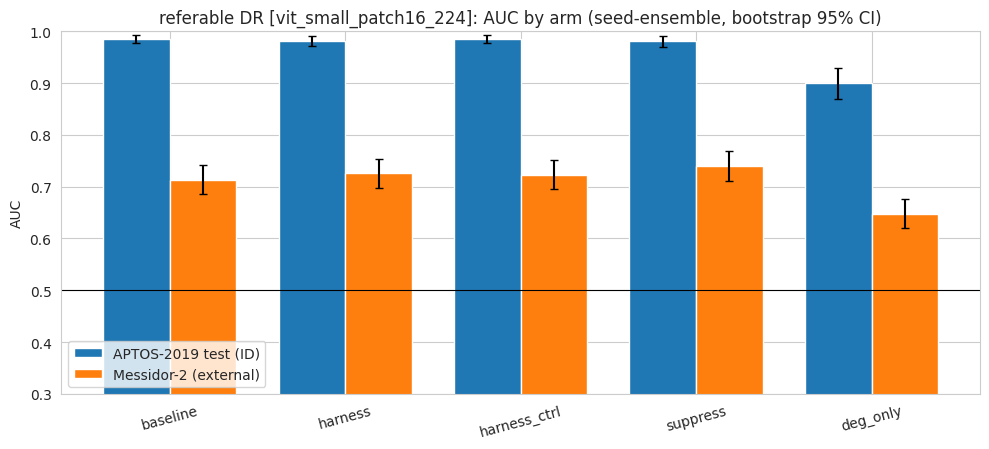

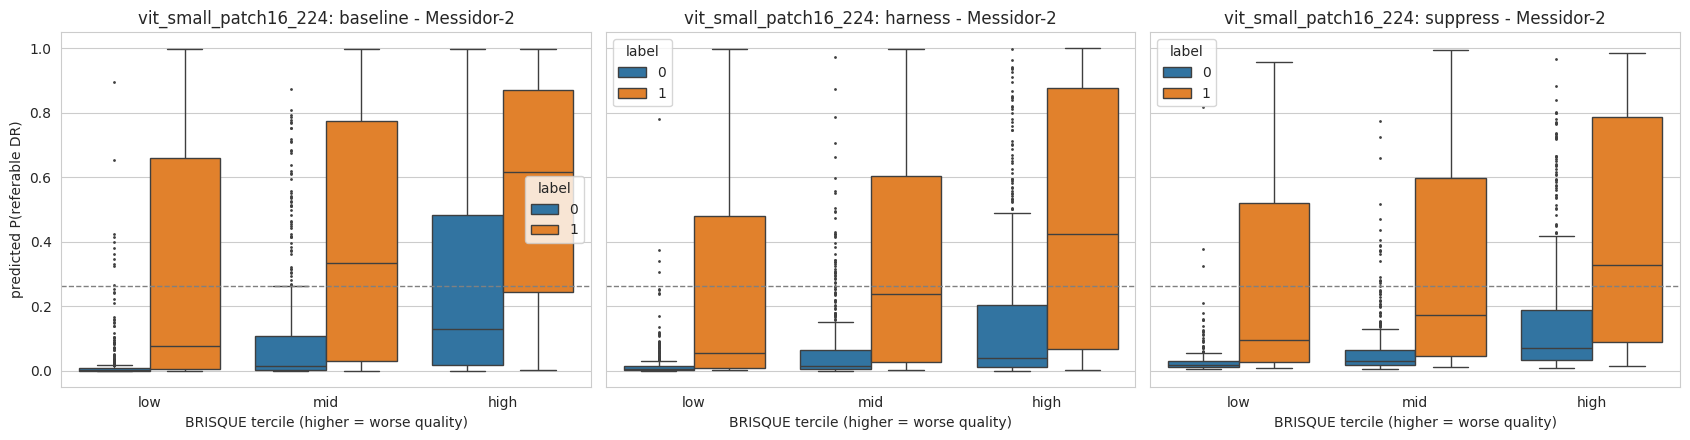

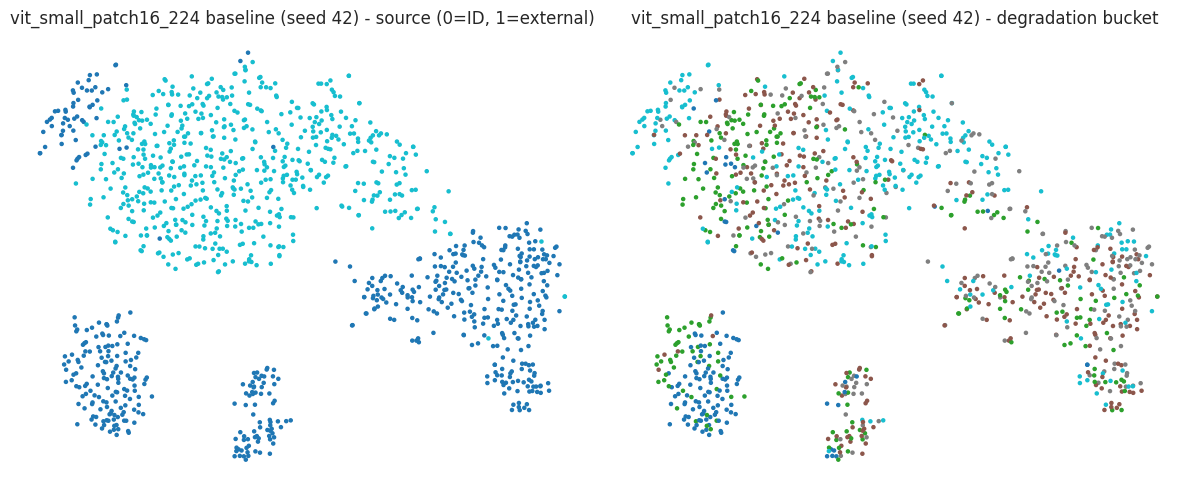

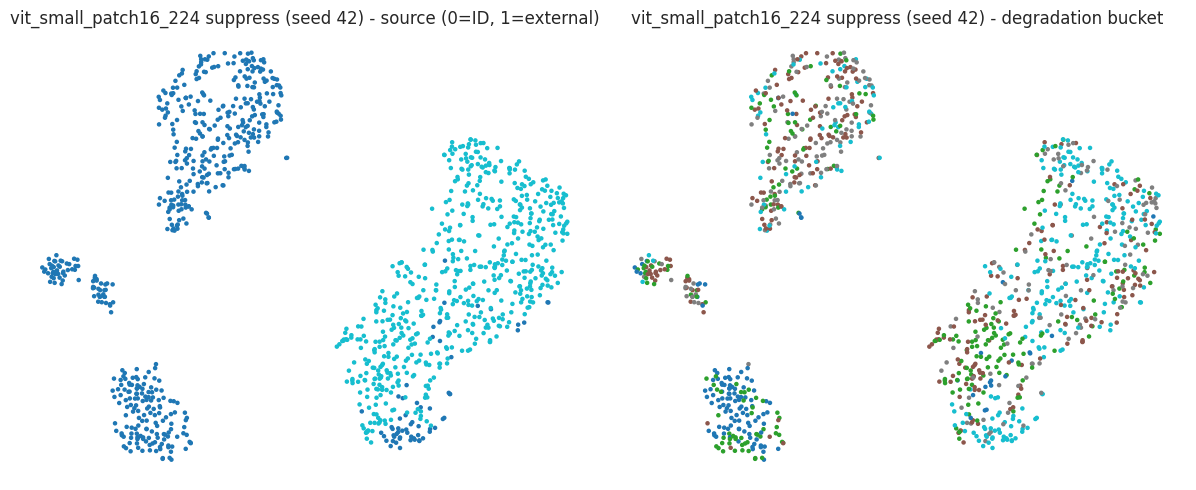

[backbone] densenet121: feat_dim=1024 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING densenet121 ==============================
[densenet121] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [densenet121] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.981     0.728
    baseline     7    0.978     0.732
    baseline  2024    0.978     0.726
    baseline    11    0.979     0.716
    baseline    99    0.973     0.773
     harness    42    0.976     0.769
     harness     7    0.980     0.744
     harness  2024    0.978     0.765
     harness    11    0.977     0.734
     harness    99    0.974     0.716
harness_ctrl    42    0.982     0.742
harness_ctrl     7    0.979     0.734
harness_ctrl  2024    0.983     0.750
harness_ctrl    11    0.975     0.719
harness_ctrl    99    0.984     0.752
    suppress    42    0.980     0.788
    suppress     7    0.973     0.776
    suppress  2024    

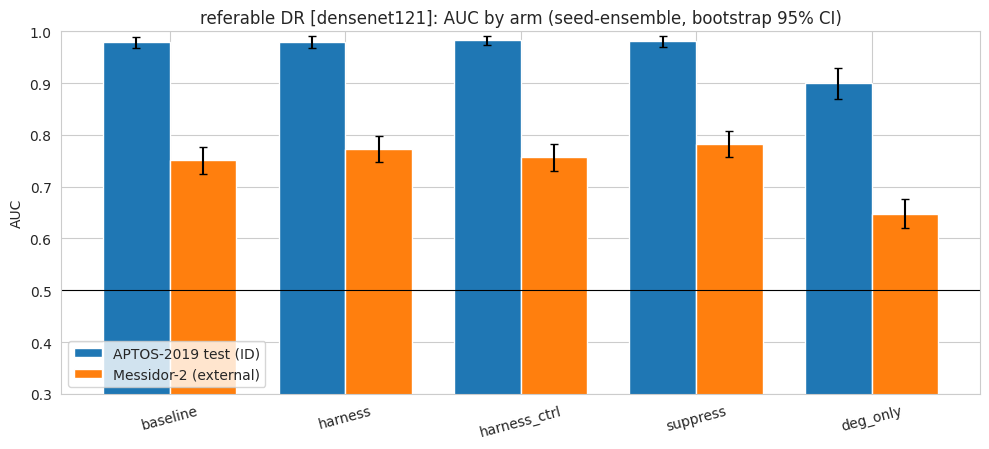

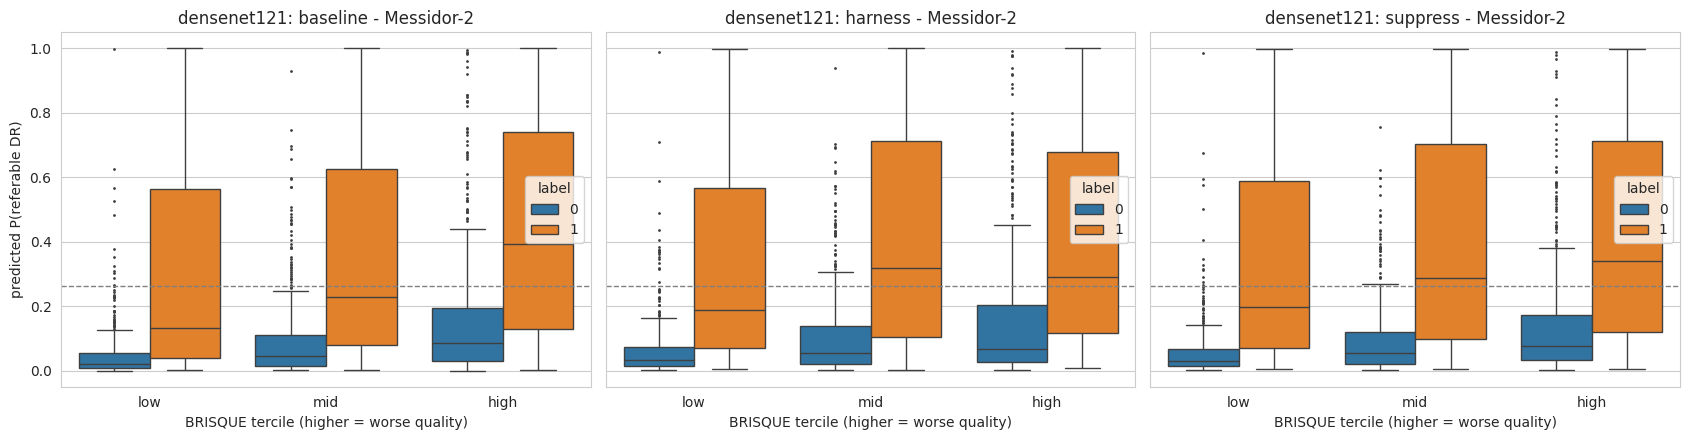

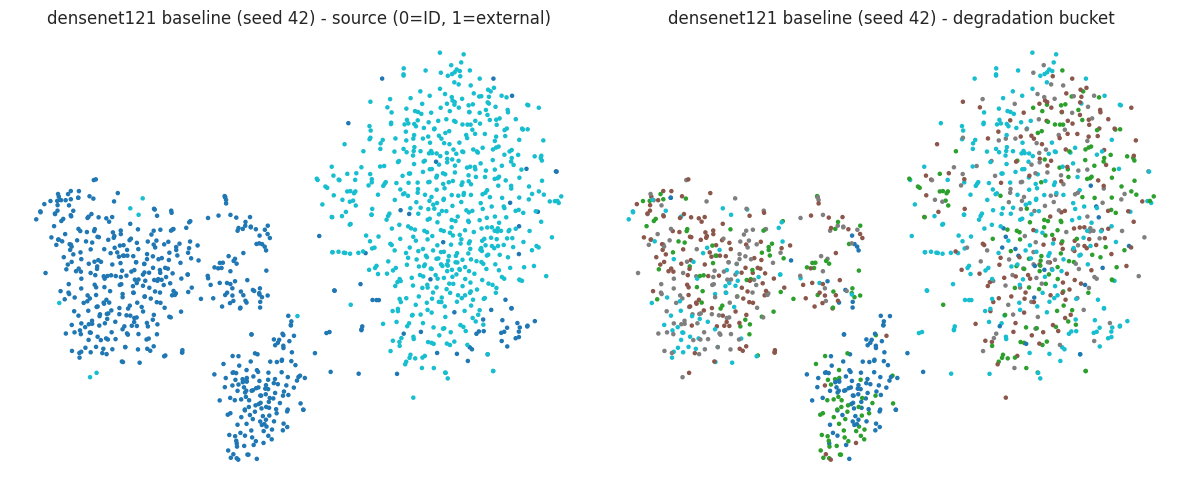

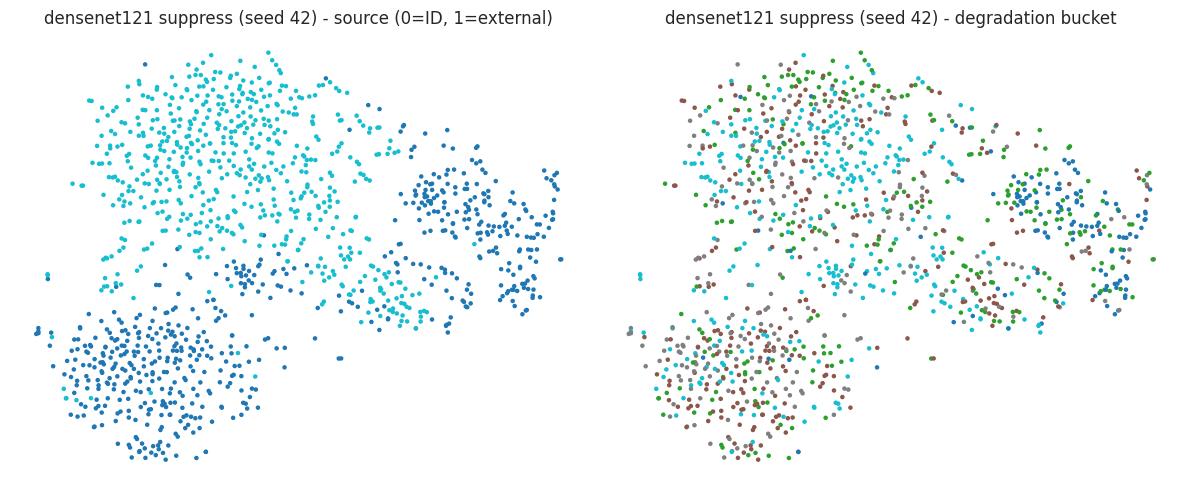

[backbone] efficientnet_b0: feat_dim=1280 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING efficientnet_b0 ==============================
[efficientnet_b0] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [efficientnet_b0] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.975     0.756
    baseline     7    0.974     0.759
    baseline  2024    0.973     0.764
    baseline    11    0.976     0.724
    baseline    99    0.975     0.777
     harness    42    0.979     0.764
     harness     7    0.971     0.794
     harness  2024    0.975     0.775
     harness    11    0.976     0.751
     harness    99    0.977     0.803
harness_ctrl    42    0.979     0.764
harness_ctrl     7    0.971     0.792
harness_ctrl  2024    0.974     0.773
harness_ctrl    11    0.976     0.746
harness_ctrl    99    0.977     0.794
    suppress    42    0.969     0.756
    suppress     7    0.974     0.727
    su

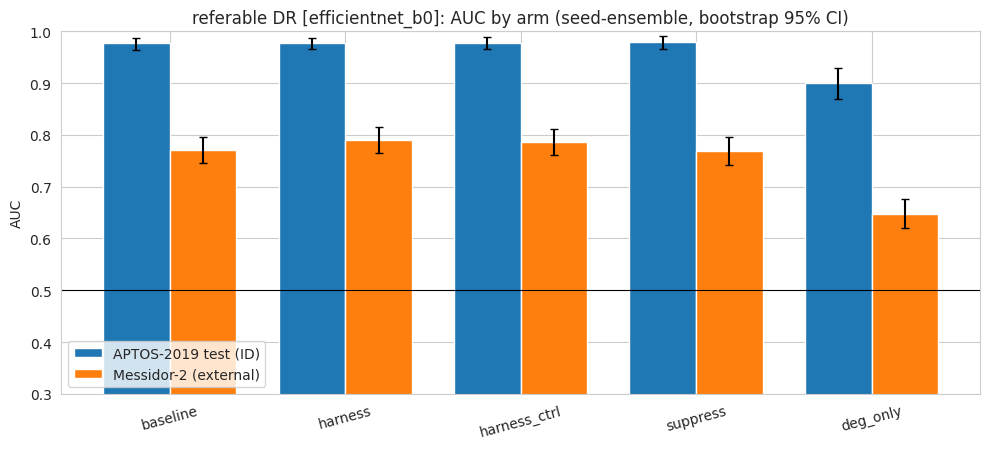

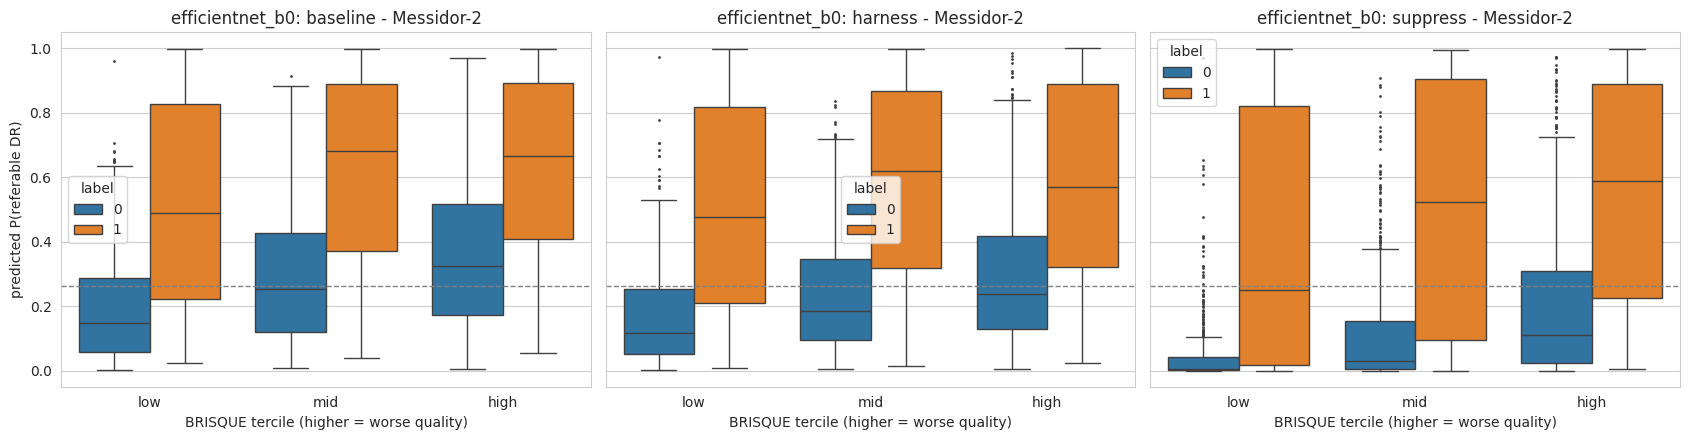

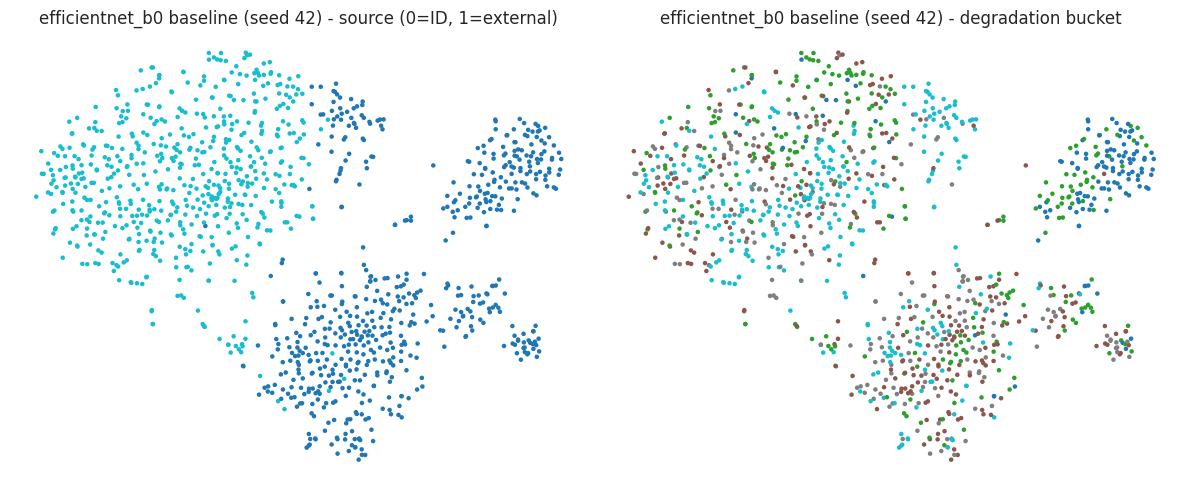

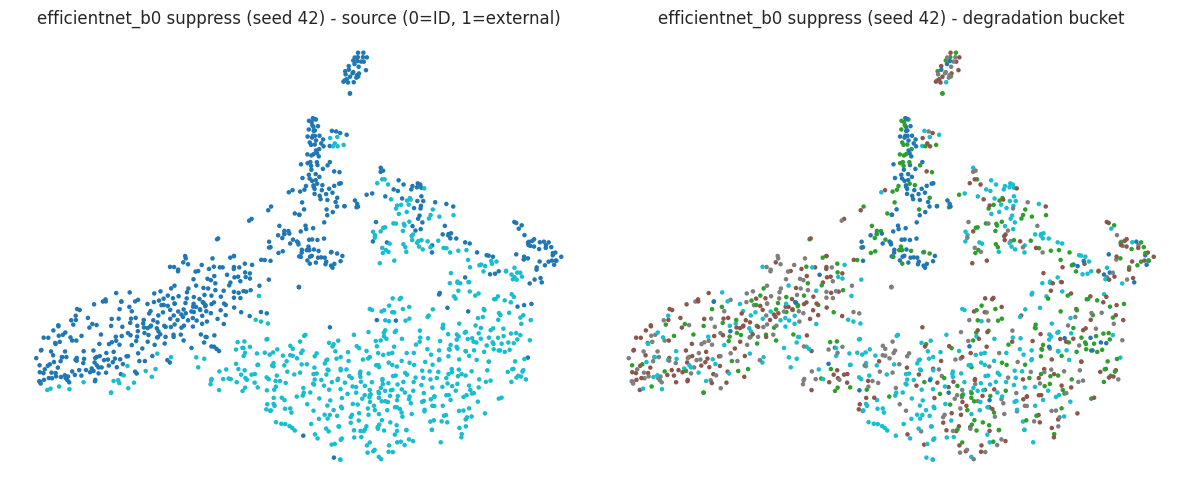

[backbone] swin_tiny_patch4_window7_224: feat_dim=768 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)

============================== EVALUATING swin_tiny_patch4_window7_224 ==============================
[swin_tiny_patch4_window7_224] checkpoint round-trip OK; max |logged - reloaded| val AUC = 0.0000
--- [swin_tiny_patch4_window7_224] per-seed AUCs ---
         arm  seed  id_test  external
    baseline    42    0.976     0.798
    baseline     7    0.979     0.785
    baseline  2024    0.981     0.810
    baseline    11    0.979     0.819
    baseline    99    0.982     0.831
     harness    42    0.979     0.844
     harness     7    0.974     0.802
     harness  2024    0.979     0.816
     harness    11    0.978     0.796
     harness    99    0.977     0.845
harness_ctrl    42    0.979     0.824
harness_ctrl     7    0.977     0.814
harness_ctrl  2024    0.979     0.821
harness_ctrl    11    0.978     0.798
harness_ctrl    99    0.976     0.804
    suppress    42    0.977    

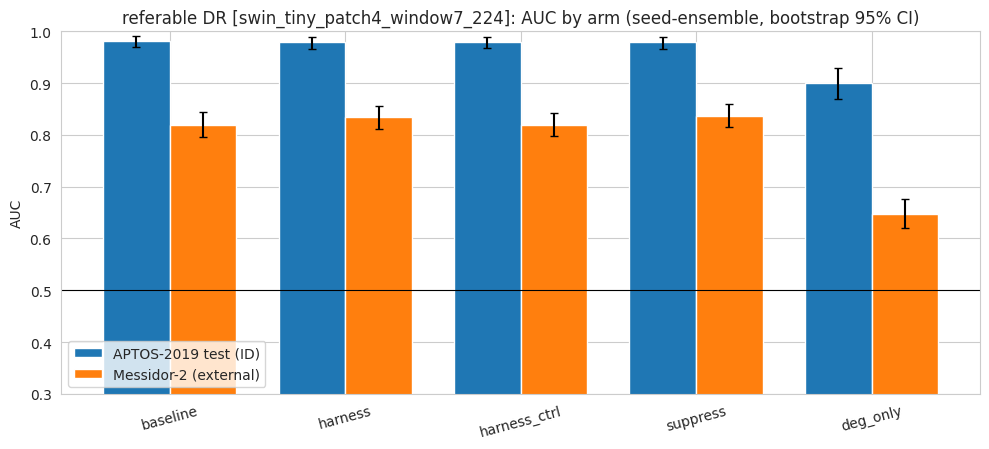

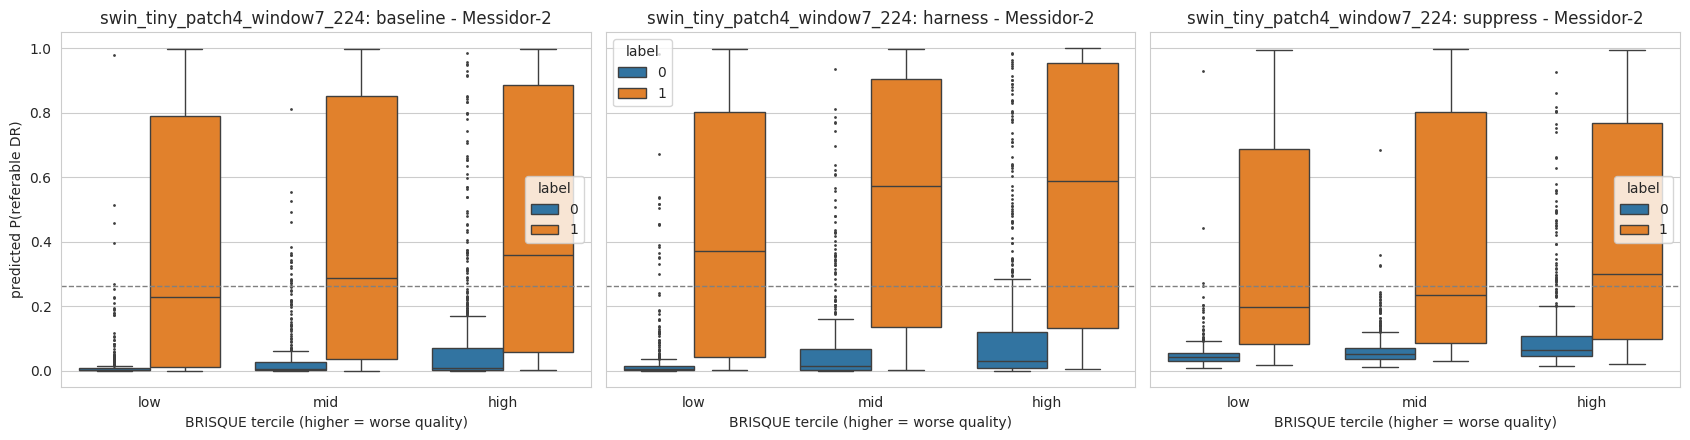

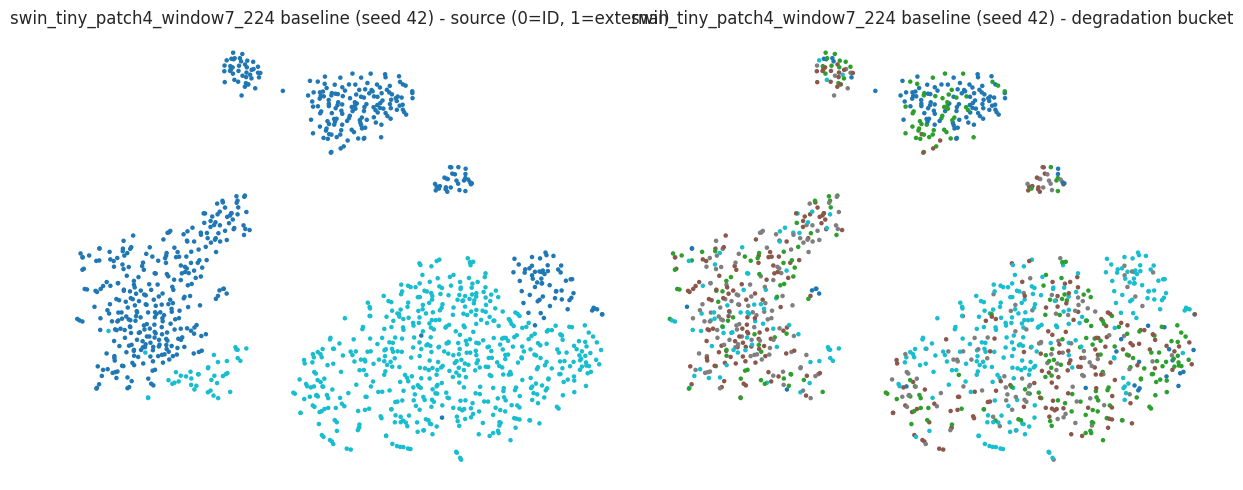

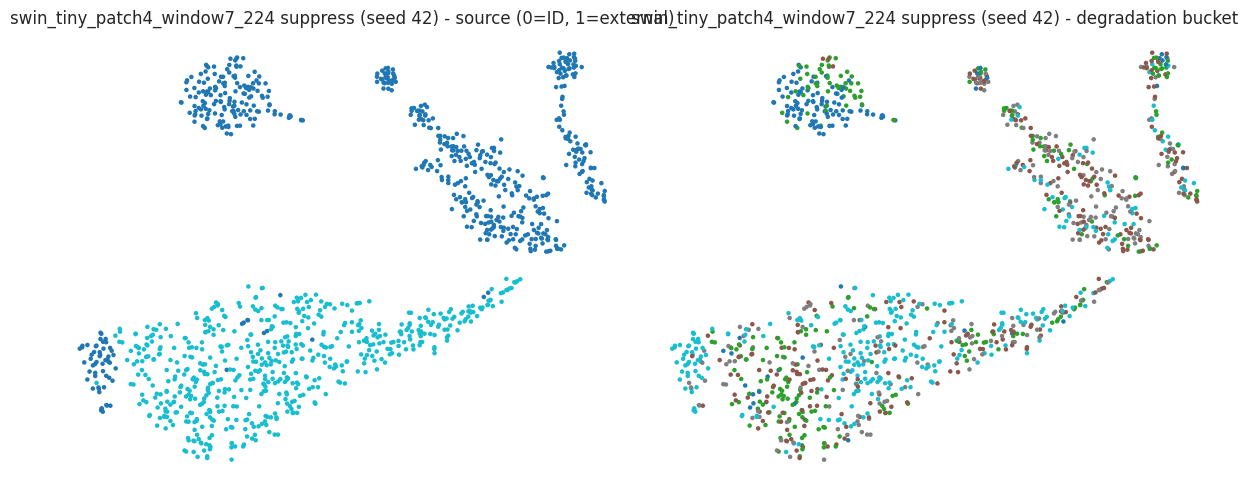

In [10]:
# One loop over the backbones. For each: reload every saved full model, evaluate, write tables/figures tagged <TAG>_<backbone>.
# (Variables below are deliberately left in the notebook namespace after the loop, so the last backbone can be inspected.)
BBS_DONE = []
for BB_ in BACKBONES:
    set_backbone(BB_); ARMS = ARMS_FOR[BB_]; TAGB = f'{TAG}_{BB_}'
    print('\n' + '=' * 30, 'EVALUATING', BB_, '=' * 30)
    # =========================== 6a. inference with the FULL saved model (backbone + all heads) ===========================
    SEEDS_OK = [s for s in SEEDS if all(ckpt_valid(ckpt_path(m, s)) is not None for m in ARMS)]
    if not SEEDS_OK:
        print(f'[{BB}] no seed has valid checkpoints for ALL arms (time budget / other session) - skipped here.'); continue
    if len(SEEDS_OK) < 3:
        print(f'[{BB}] WARNING: only {len(SEEDS_OK)} complete seed(s): {SEEDS_OK} - report this honestly in the paper.')
    PROBE_SEEDS = SEEDS_OK[:PROBE_SEEDS_N]
    va_feat = FD[FD.source == SRC_VA].reset_index(drop=True)
    te_feat = FD[FD.source == SRC_TE].reset_index(drop=True)
    ex_feat = FD[FD.source == SRC_EX].reset_index(drop=True)
    Y = {'va': va_feat.label.values.astype(int), 'te': te_feat.label.values.astype(int), 'ex': ex_feat.label.values.astype(int)}
    SPLIT_NAME = {'te': f'{NAME_ID} test (ID)', 'ex': f'{NAME_EX} (external)'}

    @torch.no_grad()
    def run_ckpt(mode, seed, dfs, want_feats=(), deg_mode=None):
        """deg_mode (test-time intervention, harness-type arms only): None = real degradation vector; 'zero' = train-mean fill (z-score 0);
        'shuffle' = vectors permuted across the images of the evaluated set (breaks the image<->degradation link)."""
        c = ckpt_valid(ckpt_path(mode, seed))
        bb, fwd, extra, ph = make_model(mode, pretrained=False)
        bb.load_state_dict(c['bb'])
        assert len(extra) == len(c['extra']), 'head count mismatch between model and checkpoint'
        for m, sd in zip(extra, c['extra']):
            m.load_state_dict(sd)                                   # every saved head state IS consumed
        bb.eval(); [m.eval() for m in extra]
        out = {}
        for k, df in dfs.items():
            perm = np.random.default_rng(seed + 1).permutation(len(df)) if mode == 'harness_ctrl' else None
            ds_ = DS(df, eval_tf, perm)
            if deg_mode == 'zero': ds_.deg = torch.zeros_like(ds_.deg)
            elif deg_mode == 'shuffle': ds_.deg = ds_.deg[torch.from_numpy(np.random.default_rng(123).permutation(len(ds_)))]
            ld = _loader(ds_, 64, False, persistent=False)
            ps, fs = [], []
            for img, y, deg, bkt in ld:
                with torch.autocast(device_type='cuda', enabled=AMP):
                    logits, f = fwd(img.to(DEVICE), deg.to(DEVICE).float())
                ps.append(logits.float().softmax(1)[:, 1].cpu())
                if k in want_feats: fs.append(f.float().cpu())
            out[k] = (torch.cat(ps).numpy(), torch.cat(fs).numpy() if fs else None)
        del bb, fwd, extra, ph; torch.cuda.empty_cache()
        return out, c['val_auc']

    P = {m: {} for m in ARMS}          # P[arm][seed] = {'va','te','ex'} probabilities
    FEATS_PS = {m: {} for m in ARMS}   # penultimate features (probe seeds only)
    sanity = []
    for seed in SEEDS_OK:
        for mode in ARMS:
            want = ('va', 'te', 'ex') if seed in PROBE_SEEDS else ()
            out, logged = run_ckpt(mode, seed, {'va': va_feat, 'te': te_feat, 'ex': ex_feat}, want)
            P[mode][seed] = {k: out[k][0] for k in ('va', 'te', 'ex')}
            if want: FEATS_PS[mode][seed] = {k: out[k][1] for k in ('va', 'te', 'ex')}
            re_auc = roc_auc_score(Y['va'], P[mode][seed]['va'])
            sanity.append({'arm': mode, 'seed': seed, 'val_auc_logged': logged, 'val_auc_reloaded': re_auc})
            # DATA-AGNOSTIC SANITY GUARD: the reloaded model must reproduce the validation AUC logged during training
            if abs(re_auc - logged) > 0.02:
                raise RuntimeError(f'CHECKPOINT ROUND-TRIP FAILED for {mode}/s{seed}: logged {logged:.3f} vs reloaded {re_auc:.3f} '
                                   '(heads not loaded / wrong feature path). Do NOT use any number below.')
    sanity = pd.DataFrame(sanity); sanity.to_csv(f'{RES}/sanity_roundtrip_{TAGB}.csv', index=False)
    print(f'[{BB}] checkpoint round-trip OK; max |logged - reloaded| val AUC = %.4f' % (sanity.val_auc_logged - sanity.val_auc_reloaded).abs().max())

    # ensemble = mean of PROBABILITIES over seeds (not mean of AUCs)
    PE = {m: {k: np.mean([P[m][s][k] for s in SEEDS_OK], axis=0) for k in ('va', 'te', 'ex')} for m in ARMS}
    PE['deg_only'] = dict(DEG_SCORE)                      # degradation-features-only logistic regression (no image)
    ALL_ROWS = ARMS + ['deg_only']
    sa = pd.DataFrame([{'arm': m, 'seed': s, 'id_test': roc_auc_score(Y['te'], P[m][s]['te']), 'external': roc_auc_score(Y['ex'], P[m][s]['ex'])}
                       for m in ARMS for s in SEEDS_OK])
    print(f'--- [{BB}] per-seed AUCs ---'); print(sa.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
    sa.to_csv(f'{RES}/table2_seeds_{TAGB}.csv', index=False)

    # =========================== 6b. paper tables ===========================
    def boot_auc(y, p, n=2000, seed=1):
        rng = np.random.default_rng(seed); y = np.asarray(y); p = np.asarray(p); a = []
        for _ in range(n):
            idx = rng.integers(0, len(y), len(y))
            if y[idx].min() == y[idx].max(): continue
            a.append(roc_auc_score(y[idx], p[idx]))
        return float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))

    def paired_delta_auc(y, p1, p2, n=2000, seed=1):
        """Bootstrap of AUC(p1)-AUC(p2) on the SAME resampled indices."""
        rng = np.random.default_rng(seed); y = np.asarray(y); p1 = np.asarray(p1); p2 = np.asarray(p2); d = []
        for _ in range(n):
            idx = rng.integers(0, len(y), len(y))
            if y[idx].min() == y[idx].max(): continue
            d.append(roc_auc_score(y[idx], p1[idx]) - roc_auc_score(y[idx], p2[idx]))
        d = np.asarray(d); lo, hi = np.percentile(d, [2.5, 97.5])
        p = max(2.0 * min((d <= 0).mean(), (d >= 0).mean()), 1.0 / (len(d) + 1))
        return float(d.mean()), float(lo), float(hi), float(min(1.0, p))

    def holm(pvals):
        p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
        for rank, i in enumerate(order):
            run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
        return adj

    def ece(y, p, n_bins=10):
        y = np.asarray(y); p = np.asarray(p); edges = np.linspace(0, 1, n_bins + 1); e = 0.0
        for i in range(n_bins):
            m = (p > edges[i]) & (p <= edges[i + 1]) if i else (p <= edges[i + 1])
            if m.sum(): e += m.mean() * abs(y[m].mean() - p[m].mean())
        return float(e)

    def youden_threshold(y, p):
        ts = np.unique(p); best, bt = -1, 0.5
        for t in ts[:: max(1, len(ts) // 400)]:
            sens = ((p >= t) & (y == 1)).sum() / max(1, (y == 1).sum()); spec = ((p < t) & (y == 0)).sum() / max(1, (y == 0).sum())
            if sens + spec - 1 > best: best, bt = sens + spec - 1, t
        return float(bt)

    # ---- Table 2: main results (ensemble AUC + CI, per-seed mean+-std, AUPRC, ECE, sens/spec at the ID-val Youden threshold) ----
    rows = []
    for m in ALL_ROWS:
        thr = youden_threshold(Y['va'], PE[m]['va'])
        for k in ('te', 'ex'):
            y, p = Y[k], PE[m][k]; lo, hi = boot_auc(y, p)
            r = {'arm': m, 'eval': k, 'AUC_ens': roc_auc_score(y, p), 'CI_lo': lo, 'CI_hi': hi,
                 'AUPRC': average_precision_score(y, p), 'prevalence': y.mean(),
                 'sens@IDthr': ((p >= thr) & (y == 1)).sum() / max(1, (y == 1).sum()),
                 'spec@IDthr': ((p < thr) & (y == 0)).sum() / max(1, (y == 0).sum()), 'n': len(y)}
            t90 = np.quantile(p[y == 0], 0.90); t95 = np.quantile(p[y == 0], 0.95)          # per-set operating points (optimistic: threshold tuned on the evaluated set)
            r['sens@spec90'] = float((p[y == 1] > t90).mean()); r['sens@spec95'] = float((p[y == 1] > t95).mean())
            if m in ARMS:
                col = 'id_test' if k == 'te' else 'external'
                r.update({'AUC_seed_mean': sa[sa.arm == m][col].mean(), 'AUC_seed_std': sa[sa.arm == m][col].std(), 'ECE': ece(y, p)})
            rows.append(r)
    res = pd.DataFrame(rows)
    print(f'--- [{BB}] Table 2: main results ---'); print(res.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
    res.to_csv(f'{RES}/table2_main_{TAGB}.csv', index=False)

    # ---- Table 2b: paired bootstrap dAUC (ensemble) + per-seed consistency + Holm correction ----
    COMPS = [c for c in [('harness', 'baseline'), ('harness', 'harness_ctrl'), ('suppress', 'baseline'), ('aug', 'baseline'),
                         ('suppress', 'harness'), ('aug', 'suppress'), ('aug_strong', 'baseline'), ('harness_brisque', 'baseline'),
                         ('harness', 'harness_brisque'), ('harness', 'aug')] if c[0] in ARMS and c[1] in ARMS]
    dl = []
    for k in ('te', 'ex'):
        for a, b in COMPS:
            m_, lo, hi, pv = paired_delta_auc(Y[k], PE[a][k], PE[b][k])
            per_seed = np.array([roc_auc_score(Y[k], P[a][s][k]) - roc_auc_score(Y[k], P[b][s][k]) for s in SEEDS_OK])
            dl.append({'eval': {'te': 'id_test', 'ex': 'external'}[k], 'comparison': f'{a} - {b}', 'dAUC': m_, 'CI_lo': lo, 'CI_hi': hi,
                       'p_value': pv, 'seed_dAUC_mean': per_seed.mean(), 'seed_dAUC_std': per_seed.std(ddof=1) if len(per_seed) > 1 else np.nan,
                       'seeds_same_sign': int((np.sign(per_seed) == np.sign(per_seed.mean())).sum()), 'n_seeds': len(per_seed)})
    delt = pd.DataFrame(dl)
    delt['p_holm'] = np.nan
    for ev in delt['eval'].unique():
        ix = delt.index[delt['eval'] == ev]; delt.loc[ix, 'p_holm'] = holm(delt.loc[ix, 'p_value'].values)
    print(f'--- [{BB}] Table 2b: paired dAUC ---'); print(delt.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
    delt.to_csv(f'{RES}/table2b_deltas_{TAGB}.csv', index=False)

    # ---- Table 3: AUC within BRISQUE terciles (within each evaluation set) + stratum-averaged AUC ----
    tr_rows = []
    for k, dfk in (('te', te_feat), ('ex', ex_feat)):
        terc = pd.qcut(dfk['brisque'], 3, labels=['low', 'mid', 'high']).astype(str).values
        for m in ALL_ROWS:
            aucs, ns = [], []
            for t in ['low', 'mid', 'high']:
                ix = terc == t; yy = Y[k][ix]
                if ix.sum() > 10 and 0 < yy.sum() < ix.sum():
                    a = roc_auc_score(yy, PE[m][k][ix]); aucs.append(a); ns.append(ix.sum())
                    tr_rows.append({'eval': k, 'arm': m, 'tercile': t, 'AUC': a, 'n': int(ix.sum()), 'n_pos': int(yy.sum())})
            if aucs:
                tr_rows.append({'eval': k, 'arm': m, 'tercile': 'STRATUM-MEAN', 'AUC': float(np.average(aucs, weights=ns)), 'n': int(sum(ns)), 'n_pos': -1})
    terc_df = pd.DataFrame(tr_rows)
    print(f'--- [{BB}] Table 3: AUC within degradation terciles ---')
    print(terc_df.pivot_table(index=['eval', 'arm'], columns='tercile', values='AUC').round(3).to_string())
    terc_df.to_csv(f'{RES}/table3_terciles_{TAGB}.csv', index=False)

    # ---- Table 7: shortcut reliance = rank correlation of each arm's score with the degradation-only score / raw BRISQUE ----
    sc = []
    for k, dfk in (('te', te_feat), ('ex', ex_feat)):
        for m in ARMS:
            sc.append({'eval': k, 'arm': m, 'spearman_vs_deg_only_score': spearmanr(PE[m][k], PE['deg_only'][k])[0],
                       'spearman_vs_BRISQUE': spearmanr(PE[m][k], dfk['brisque'].values)[0]})
    sc = pd.DataFrame(sc); print(f'--- [{BB}] Table 7: score <-> degradation correlation ---'); print(sc.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
    sc.to_csv(f'{RES}/table7_score_degradation_corr_{TAGB}.csv', index=False)

    # ---- Table 8: does the arm's benefit TRANSFER?  gap = dAUC(external) - dAUC(ID); independent bootstrap over the two test sets ----
    def transfer_gap(y_id, a_id, b_id, y_ex, a_ex, b_ex, n=2000, seed=3):
        rng = np.random.default_rng(seed); g = []
        for _ in range(n):
            i = rng.integers(0, len(y_id), len(y_id)); j = rng.integers(0, len(y_ex), len(y_ex))
            if y_id[i].min() == y_id[i].max() or y_ex[j].min() == y_ex[j].max(): continue
            g.append((roc_auc_score(y_ex[j], a_ex[j]) - roc_auc_score(y_ex[j], b_ex[j])) - (roc_auc_score(y_id[i], a_id[i]) - roc_auc_score(y_id[i], b_id[i])))
        g = np.asarray(g); lo, hi = np.percentile(g, [2.5, 97.5])
        return float(g.mean()), float(lo), float(hi), float(min(1.0, max(2 * min((g <= 0).mean(), (g >= 0).mean()), 1 / (len(g) + 1))))
    tg = []
    for a, b in [c for c in [('harness', 'baseline'), ('suppress', 'baseline'), ('aug', 'baseline'), ('harness', 'harness_ctrl'), ('aug_strong', 'baseline'), ('harness_brisque', 'baseline')] if c[0] in ARMS and c[1] in ARMS]:
        m_, lo, hi, pv = transfer_gap(Y['te'], PE[a]['te'], PE[b]['te'], Y['ex'], PE[a]['ex'], PE[b]['ex'])
        tg.append({'comparison': f'{a} - {b}', 'gap_ext_minus_id': m_, 'CI_lo': lo, 'CI_hi': hi, 'p_value': pv})
    tg = pd.DataFrame(tg); tg['p_holm'] = holm(tg.p_value.values)
    print(f'--- [{BB}] Table 8: transfer gap of each arm benefit (negative = benefit does NOT transfer) ---')
    print(tg.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
    tg.to_csv(f'{RES}/table8_transfer_gap_{TAGB}.csv', index=False)


    # ---- Table 13: TEST-TIME INTERVENTION on the degradation input of harness-type models (causal use of the degradation vector) ----
    # same trained weights, only the degradation vector fed at inference changes: real / zero (train mean) / shuffled across images.
    # If the harness benefit is really *used* information, AUC(real) > AUC(zero) ~ AUC(shuffle); if AUC(zero) ~ AUC(real), the vector is ignored
    # and any ID/OOD difference vs baseline is just a different optimisation path.
    iv_rows = []; INTV = {}      # INTV[(arm, dm)][seed][k] = probabilities with the degradation vector intervened on
    for mode in [m for m in ('harness', 'harness_brisque') if m in ARMS]:
        PI = {dm: {} for dm in ('real', 'zero', 'shuffle')}
        for seed in SEEDS_OK:
            for dm in ('zero', 'shuffle'):
                out, _ = run_ckpt(mode, seed, {'te': te_feat, 'ex': ex_feat}, deg_mode=dm)
                PI[dm][seed] = {k: out[k][0] for k in ('te', 'ex')}
            PI['real'][seed] = {k: P[mode][seed][k] for k in ('te', 'ex')}
        if mode == 'harness': INTV = {('harness', dm): PI[dm] for dm in ('zero', 'shuffle')}
        for k in ('te', 'ex'):
            ens = {dm: np.mean([PI[dm][s][k] for s in SEEDS_OK], axis=0) for dm in PI}
            for dm in ('zero', 'shuffle'):
                d_, lo_, hi_, p_ = paired_delta_auc(Y[k], ens['real'], ens[dm])
                ps_ = np.array([roc_auc_score(Y[k], PI['real'][s][k]) - roc_auc_score(Y[k], PI[dm][s][k]) for s in SEEDS_OK])
                bl_ = roc_auc_score(Y[k], PE['baseline'][k]) if 'baseline' in PE else np.nan
                iv_rows.append({'arm': mode, 'eval': {'te': 'id_test', 'ex': 'external'}[k], 'intervention': dm,
                                'AUC_real': roc_auc_score(Y[k], ens['real']), 'AUC_intervened': roc_auc_score(Y[k], ens[dm]),
                                'AUC_baseline_arm': bl_, 'drop(real-intervened)': d_, 'CI_lo': lo_, 'CI_hi': hi_, 'p_value': p_,
                                'seeds_drop_positive': f'{int((ps_ > 0).sum())}/{len(ps_)}'})
    iv_df = pd.DataFrame(iv_rows)
    if len(iv_df):
        print(f'--- [{BB}] Table 13: test-time intervention on the degradation vector (drop > 0 => the model USES it) ---')
        print(iv_df.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
        iv_df.to_csv(f'{RES}/table13_intervention_{TAGB}.csv', index=False)
    # ---- Table 14: the harness model with its degradation channel REMOVED at test time ('harness_zero') as a deployable arm ----
    EXTRA_PRED, EXTRA_SEED = {}, {}
    if INTV:
        t14 = []
        for dm in ('zero', 'shuffle'):
            nm = f'harness_{dm}'
            EXTRA_PRED[nm] = {k: np.mean([INTV[('harness', dm)][s][k] for s in SEEDS_OK], axis=0) for k in ('te', 'ex')}
            for s in SEEDS_OK:
                for k in ('te', 'ex'): EXTRA_SEED[f'ps_{nm}_{s}_{k}'] = INTV[('harness', dm)][s][k]
        for k in ('te', 'ex'):
            for dm in ('zero', 'shuffle'):
                for ref in ('baseline', 'harness'):
                    d_, lo_, hi_, p_ = paired_delta_auc(Y[k], EXTRA_PRED[f'harness_{dm}'][k], PE[ref][k])
                    t14.append({'eval': {'te': 'id_test', 'ex': 'external'}[k], 'comparison': f'harness_{dm} - {ref}', 'AUC_harness_variant': roc_auc_score(Y[k], EXTRA_PRED[f'harness_{dm}'][k]),
                                'dAUC': d_, 'CI_lo': lo_, 'CI_hi': hi_, 'p_value': p_})
        t14 = pd.DataFrame(t14); t14['p_holm'] = holm(t14.p_value.values)
        print(f'--- [{BB}] Table 14: harness model with the degradation vector zeroed / shuffled at test time vs baseline and vs the normal harness ---')
        print(t14.to_string(index=False, float_format=lambda v: f'{v:.4f}')); t14.to_csv(f'{RES}/table14_harness_variants_{TAGB}.csv', index=False)

    np.savez_compressed(f'{RES}/preds_{TAGB}.npz', y_id=Y['te'], y_ex=Y['ex'], y_va=Y['va'], brisque_id=te_feat['brisque'].values,
                        brisque_ex=ex_feat['brisque'].values,
                        **{f'p_{m}_{k}': PE[m][k] for m in ALL_ROWS for k in ('va', 'te', 'ex')},
                        **{f'p_{m}_{k}': EXTRA_PRED[m][k] for m in EXTRA_PRED for k in ('te', 'ex')},
                        **{f'ps_{m}_{s}_{k}': P[m][s][k] for m in ARMS for s in SEEDS_OK for k in ('te', 'ex')},
                        **EXTRA_SEED)
    print('saved ensemble predictions ->', f'preds_{TAGB}.npz')

    # =========================== 6c. forensic probes (held-out, per seed, within-domain) ===========================
    # What changed vs the first version (and why):
    #  * features are NEVER averaged across seeds (coordinates of independently trained networks are not aligned) -> probe each seed, then average;
    #  * degradation decodability is measured WITHIN each domain (otherwise the trivially decodable domain label inflates it);
    #  * quintile buckets are re-computed within each domain -> chance is exactly 0.20 (domain probe chance = 0.50, classes balanced);
    #  * a continuous test is added: held-out R^2 of ridge regression onto the z-scored degradation features (suppress only targets BRISQUE buckets,
    #    so leakage of the OTHER degradation features is the interesting part).
    from sklearn.metrics import r2_score
    BR_IDX = FEATS.index('brisque')
    Xz = {k: X[m] for k, m in (('va', va_mask), ('te', te_mask), ('ex', ex_mask))}      # z-scored degradation features (train statistics)

    def clf_acc(Xm, y, k=5, seed=0):
        skf = StratifiedKFold(k, shuffle=True, random_state=seed)
        pred = cross_val_predict(make_pipeline(VarianceThreshold(1e-8), StandardScaler(), FunctionTransformer(_clip8), LogisticRegression(max_iter=300, C=0.05)), Xm, y, cv=skf)
        return float(accuracy_score(y, pred)), float(balanced_accuracy_score(y, pred))

    def ridge_r2(Xm, Tm, k=5, seed=0):
        pred = cross_val_predict(make_pipeline(VarianceThreshold(1e-8), StandardScaler(), FunctionTransformer(_clip8), RidgeCV(alphas=np.logspace(1, 4, 4))), Xm, Tm,
                                 cv=KFold(k, shuffle=True, random_state=seed))
        return r2_score(Tm, pred, multioutput='raw_values')

    fr_rows = []
    for mode in ARMS:
        for seed in PROBE_SEEDS:
            f = FEATS_PS[mode][seed]
            f_id = np.vstack([f['va'], f['te']]); d_id = np.vstack([Xz['va'], Xz['te']]); f_ex, d_ex = f['ex'], Xz['ex']
            rng = np.random.default_rng(seed); n = min(len(f_id), len(f_ex))
            ii, ee = rng.choice(len(f_id), n, replace=False), rng.choice(len(f_ex), n, replace=False)
            dom_acc, _ = clf_acc(np.vstack([f_id[ii], f_ex[ee]]), np.r_[np.zeros(n), np.ones(n)].astype(int), seed=seed)
            r = {'arm': mode, 'seed': seed, 'domain_acc(chance .5)': dom_acc}
            for nm, ff, dd in (('ID', f_id, d_id), ('EXT', f_ex, d_ex)):
                bq = np.asarray(pd.qcut(dd[:, BR_IDX], 5, labels=False, duplicates='drop')).astype(int)
                r[f'bucket_acc_{nm}(chance .2)'] = clf_acc(ff, bq, seed=seed)[0]
                r2 = ridge_r2(ff, dd, seed=seed)
                r[f'R2_BRISQUE_{nm}'] = float(r2[BR_IDX]); r[f'R2_allfeat_mean_{nm}'] = float(np.mean(r2))
            fr_rows.append(r)
        print(f'  forensic probes done: {mode}', end='\r')
    fr_seed = pd.DataFrame(fr_rows); fr_seed.to_csv(f'{RES}/table4_forensic_probes_perseed_{TAGB}.csv', index=False)
    fr = fr_seed.drop(columns='seed').groupby('arm').agg(['mean', 'std']).loc[ARMS]
    fr.columns = [f'{a}_{b}' for a, b in fr.columns]
    fr['task_AUC_external'] = [res[(res.arm == m) & (res['eval'] == 'ex')]['AUC_ens'].iloc[0] for m in ARMS]
    print('--- [%s] Table 4: forensic probes (mean/std over %d seed(s)); lower = less information left in the representation ---' % (BB, len(PROBE_SEEDS)))
    print(fr.round(3).T.to_string()); fr.to_csv(f'{RES}/table4_forensic_probes_{TAGB}.csv')

    # =========================== 6d. figures ===========================
    fig, ax = plt.subplots(figsize=(10, 4.6)); x = np.arange(len(ALL_ROWS)); w = 0.38
    for k, off, lab in (('te', -w / 2, SPLIT_NAME['te']), ('ex', w / 2, SPLIT_NAME['ex'])):
        d = res[res['eval'] == k].set_index('arm').loc[ALL_ROWS]
        ax.bar(x + off, d.AUC_ens, w, yerr=[np.clip(d.AUC_ens - d.CI_lo, 0, None), np.clip(d.CI_hi - d.AUC_ens, 0, None)], capsize=3, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(ALL_ROWS, rotation=15); ax.set_ylim(0.3, 1.0); ax.axhline(0.5, c='k', lw=0.8)
    ax.set_ylabel('AUC'); ax.legend(); ax.set_title(f'{TASK} [{BB}]: AUC by arm (seed-ensemble, bootstrap 95% CI)')
    plt.tight_layout(); plt.savefig(f'{RES}/fig3_auc_arms_{TAGB}.png', dpi=200); plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
    terc_ex = pd.qcut(ex_feat['brisque'], 3, labels=['low', 'mid', 'high']).astype(str).values
    for ax, mode in zip(axes, ['baseline', 'harness', 'suppress']):
        dfp = pd.DataFrame({'tercile': terc_ex, 'label': Y['ex'], 'prob': PE[mode]['ex']})
        sns.boxplot(data=dfp, x='tercile', y='prob', hue='label', order=['low', 'mid', 'high'], ax=ax, fliersize=1)
        ax.axhline(Y['ex'].mean(), ls='--', c='gray', lw=1); ax.set_title(f'{BB}: {mode} - {NAME_EX}')
        ax.set_xlabel('BRISQUE tercile (higher = worse quality)'); ax.set_ylabel(f'predicted P({TASK})')
    plt.tight_layout(); plt.savefig(f'{RES}/fig5_score_by_tercile_{TAGB}.png', dpi=200); plt.show()

    s0 = PROBE_SEEDS[0]
    for mode in ['baseline', 'suppress']:
        try:
            f = FEATS_PS[mode][s0]; f_id = np.vstack([f['va'], f['te']]); f_ex = f['ex']
            bk_id = np.concatenate([va_feat.deg_bucket.values, te_feat.deg_bucket.values]); bk_ex = ex_feat.deg_bucket.values
            rng = np.random.default_rng(0); n_sub = int(min(600, len(f_id), len(f_ex)))
            if n_sub < 40: print(f'[t-SNE] skipped {mode}: only {n_sub} samples'); continue
            ii, ee = rng.choice(len(f_id), n_sub, replace=False), rng.choice(len(f_ex), n_sub, replace=False)
            z = TSNE(n_components=2, perplexity=min(30, max(5, n_sub // 4)), random_state=SEED, init='pca').fit_transform(np.vstack([f_id[ii], f_ex[ee]]))
            src_c = np.array([0] * n_sub + [1] * n_sub); bkt = np.concatenate([bk_id[ii], bk_ex[ee]])
            fig, axes = plt.subplots(1, 2, figsize=(12, 5))
            for ax, cc, title in ((axes[0], src_c, 'source (0=ID, 1=external)'), (axes[1], bkt, 'degradation bucket')):
                ax.scatter(z[:, 0], z[:, 1], c=cc, s=5, cmap='tab10'); ax.set_title(f'{BB} {mode} (seed {s0}) - {title}'); ax.axis('off')
            plt.tight_layout(); plt.savefig(f'{RES}/fig4_tsne_{mode}_{TAGB}.png', dpi=200); plt.show()
        except Exception as e:
            print(f'[t-SNE] failed for {mode}: {e} (non-fatal)')

    BBS_DONE.append(BB_)
    torch.cuda.empty_cache()


## 7. Cross-backbone aggregation (merges other sessions' outputs automatically)

backbones found: ['resnet50', 'convnext_tiny', 'vit_small_patch16_224', 'densenet121', 'efficientnet_b0', 'swin_tiny_patch4_window7_224'] | missing: []
--- Table 10: arm effect on AUC for every backbone ---
comparison                   aug - baseline         aug_strong - baseline         harness - baseline         harness - harness_ctrl         harness_brisque - baseline         suppress - baseline        
eval                               external id_test              external id_test           external id_test               external id_test                   external id_test            external id_test
backbone                                                                                                                                                                                                  
convnext_tiny                           NaN     NaN                   NaN     NaN              0.002  -0.001                  0.006  -0.003                        NaN     NaN          

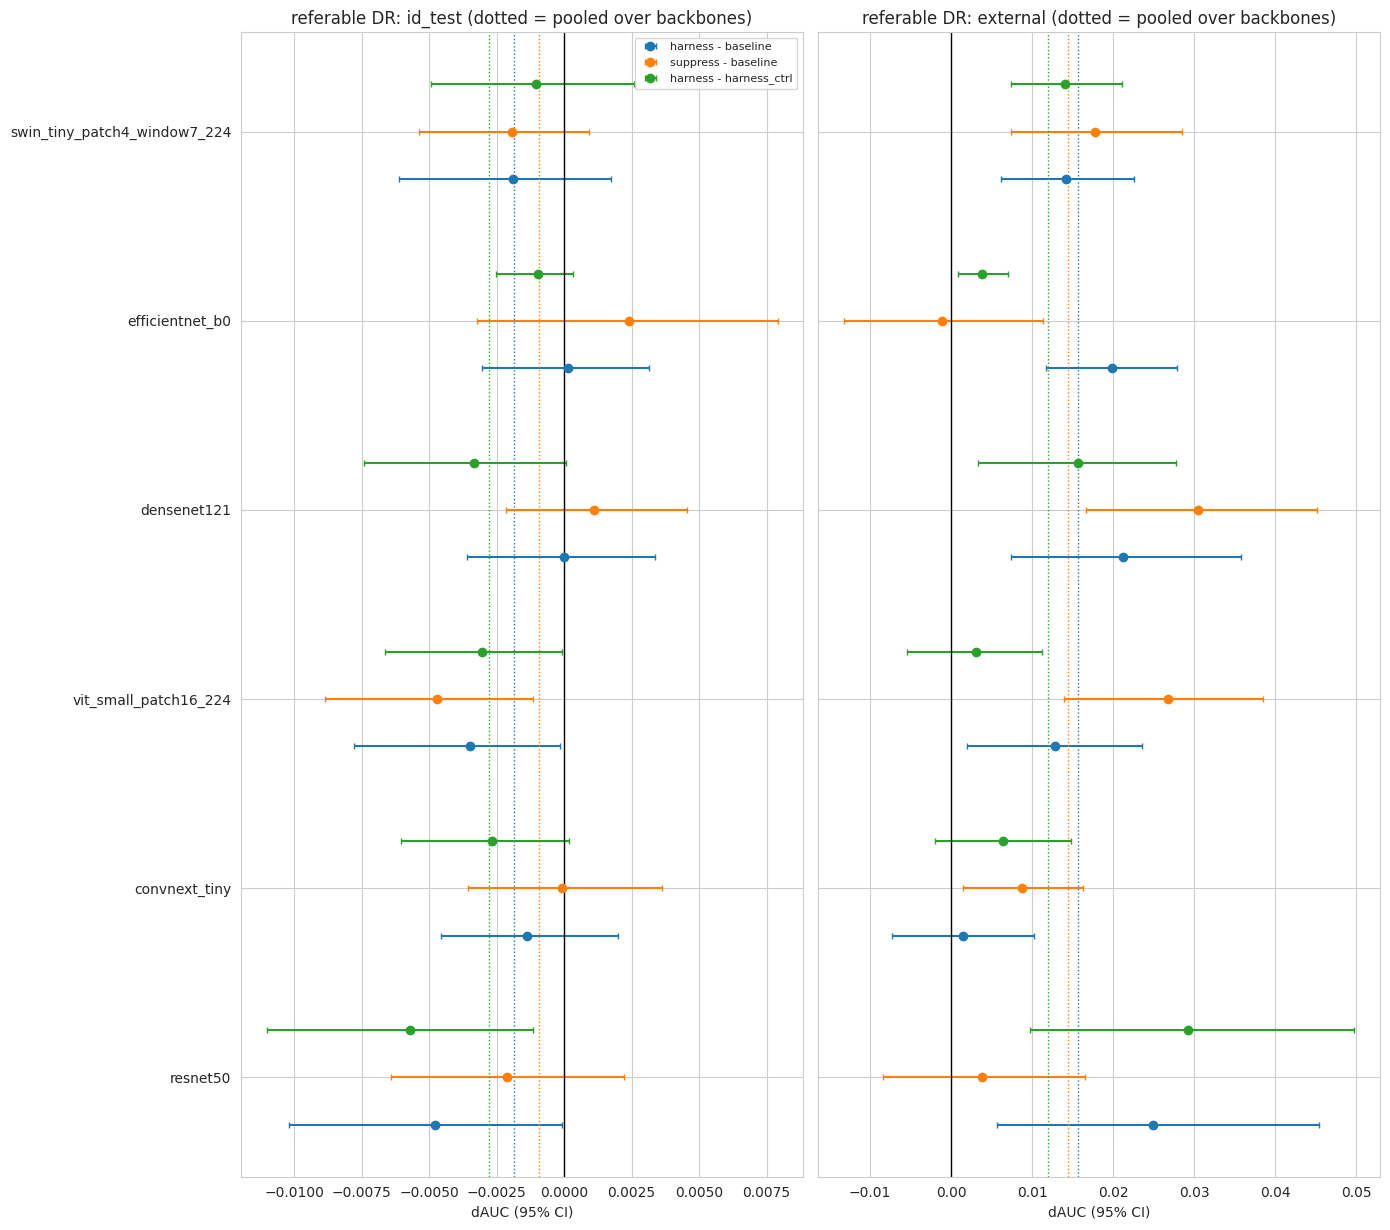

In [11]:
# =========================== 7. CROSS-BACKBONE AGGREGATION ===========================
# Reads the per-backbone files written by Section 6 from this session AND from any other session mounted under /kaggle/input
# (so a two-session split of BACKBONES is merged automatically). Writes table10/11/12 + the forest plot.
from scipy.stats import rankdata

def fast_auc(y, p):
    r = rankdata(p); n1 = int(y.sum()); n0 = len(y) - n1
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def holm_adj(pvals):
    p = np.asarray(pvals, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def find_per_backbone(prefix, ext):
    """{backbone: path} for files named <prefix>_<TAG>_<backbone>.<ext>; files from THIS session win over mounted ones."""
    out = {}
    pats = [f'/kaggle/input/**/{prefix}_{TAG}_*.{ext}', f'{RES}/{prefix}_{TAG}_*.{ext}']
    for pat in pats:                                  # later patterns overwrite earlier ones
        for p in sorted(glob.glob(pat, recursive=True)):
            bbn = os.path.basename(p)[len(f'{prefix}_{TAG}_'):-(len(ext) + 1)]
            out[bbn] = p
    return out

main_f, delt_f, pred_f = find_per_backbone('table2_main', 'csv'), find_per_backbone('table2b_deltas', 'csv'), find_per_backbone('preds', 'npz')
fore_f, tg_f = find_per_backbone('table4_forensic_probes', 'csv'), find_per_backbone('table8_transfer_gap', 'csv')
iv_f = find_per_backbone('table13_intervention', 'csv')
AGG_BB = [b for b in BACKBONES + [x for x in main_f if x not in BACKBONES] if b in main_f and b in delt_f]
print('backbones found:', AGG_BB, '| missing:', [b for b in BACKBONES if b not in AGG_BB])
assert AGG_BB, 'no per-backbone result files found - run Section 6 first.'

# ---------- Table 10: per-backbone summary of the arm effects (dAUC vs baseline, paired bootstrap, Holm over each backbone) ----------
rows = []
for b in AGG_BB:
    m = pd.read_csv(main_f[b]); d = pd.read_csv(delt_f[b])
    for ev in ('id_test', 'external'):
        k = 'te' if ev == 'id_test' else 'ex'
        base = m[(m.arm == 'baseline') & (m['eval'] == k)].iloc[0]
        for comp in ('harness - baseline', 'harness - harness_ctrl', 'suppress - baseline', 'aug - baseline', 'aug_strong - baseline', 'harness_brisque - baseline'):
            r = d[(d['eval'] == ev) & (d.comparison == comp)]
            if len(r):
                r = r.iloc[0]
                rows.append({'backbone': b, 'eval': ev, 'baseline_AUC': base.AUC_ens, 'comparison': comp, 'dAUC': r.dAUC, 'CI_lo': r.CI_lo,
                             'CI_hi': r.CI_hi, 'p_holm_within_backbone': r.p_holm, 'seeds_same_sign': f'{int(r.seeds_same_sign)}/{int(r.n_seeds)}'})
t10 = pd.DataFrame(rows); t10.to_csv(f'{RES}/table10_per_backbone_{TAG}.csv', index=False)
print('--- Table 10: arm effect on AUC for every backbone ---')
print(t10.pivot_table(index='backbone', columns=['comparison', 'eval'], values='dAUC').round(3).to_string())

# ---------- Table 11: architecture-pooled effects. Bootstrap resamples the SAME test images for every backbone (backbones share the test set) ----------
PZ = {b: np.load(pred_f[b]) for b in AGG_BB if b in pred_f}
def pooled(comp, k, n=1000, seed=5):
    a, bsl = comp.split(' - ')
    bbs = [b for b in PZ if f'p_{a}_{k}' in PZ[b] and f'p_{bsl}_{k}' in PZ[b]]
    if len(bbs) < 2: return None
    y = PZ[bbs[0]]['y_id' if k == 'te' else 'y_ex']
    assert all((PZ[b]['y_id' if k == 'te' else 'y_ex'] == y).all() for b in bbs), 'backbones were evaluated on different test sets'
    rng = np.random.default_rng(seed); D = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max(): continue
        D.append([fast_auc(y[idx], PZ[b][f'p_{a}_{k}'][idx]) - fast_auc(y[idx], PZ[b][f'p_{bsl}_{k}'][idx]) for b in bbs])
    D = np.asarray(D); pm = D.mean(1); lo, hi = np.percentile(pm, [2.5, 97.5])
    per = D.mean(0)
    return {'comparison': comp, 'eval': 'id_test' if k == 'te' else 'external', 'n_backbones': len(bbs), 'pooled_dAUC': pm.mean(), 'CI_lo': lo, 'CI_hi': hi,
            'p_value': min(1.0, max(2 * min((pm <= 0).mean(), (pm >= 0).mean()), 1 / (len(pm) + 1))),
            'backbones_positive': int((per > 0).sum()), 'backbones_sig_same_dir': int(sum((np.percentile(D[:, j], 2.5) > 0) if per[j] > 0 else (np.percentile(D[:, j], 97.5) < 0)
                                                                                         for j in range(len(bbs)) if per[j] != 0))}
POOL_COMPS = ('harness - baseline', 'harness - harness_ctrl', 'suppress - baseline', 'aug - baseline', 'harness - harness_zero', 'harness - harness_shuffle', 'harness_zero - baseline')
pr = [pooled(c, k) for c in POOL_COMPS for k in ('te', 'ex')]   # (aug arms exist for 1 backbone -> None)
t11 = pd.DataFrame([r for r in pr if r]); 
if len(t11):
    t11['p_holm'] = holm_adj(t11.p_value.values)
    print('--- Table 11: effect pooled over backbones (mean dAUC; shared-image bootstrap) ---'); print(t11.round(4).to_string(index=False))
    t11.to_csv(f'{RES}/table11_pooled_{TAG}.csv', index=False)

# ---------- Table 11b: SEED-AWARE pooled effects (bootstrap resamples test images AND training seeds; same draw for every backbone) ----------
def pooled_seedaware(comp, k, n=600, seed=9):
    a_, b_ = comp.split(' - ')
    bbs = [b for b in PZ if all(any(f'ps_{m}_{s}_{k}' in PZ[b] for s in SEEDS) for m in (a_, b_))]
    if len(bbs) < 2: return None
    seeds_all = [s for s in SEEDS if all(f'ps_{m}_{s}_{k}' in PZ[b] for b in bbs for m in (a_, b_))]
    if len(seeds_all) < 2: return None
    y = PZ[bbs[0]]['y_id' if k == 'te' else 'y_ex']; rng = np.random.default_rng(seed); D = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y)); ss = rng.choice(seeds_all, len(seeds_all), replace=True)
        if y[idx].min() == y[idx].max(): continue
        row = []
        for b in bbs:
            pa = np.mean([PZ[b][f'ps_{a_}_{s}_{k}'] for s in ss], axis=0); pb_ = np.mean([PZ[b][f'ps_{b_}_{s}_{k}'] for s in ss], axis=0)
            row.append(fast_auc(y[idx], pa[idx]) - fast_auc(y[idx], pb_[idx]))
        D.append(row)
    D = np.asarray(D); pm = D.mean(1); lo, hi = np.percentile(pm, [2.5, 97.5])
    return {'comparison': comp, 'eval': 'id_test' if k == 'te' else 'external', 'n_backbones': len(bbs), 'n_seeds': len(seeds_all), 'pooled_dAUC': pm.mean(), 'CI_lo': lo, 'CI_hi': hi,
            'p_value': min(1.0, max(2 * min((pm <= 0).mean(), (pm >= 0).mean()), 1 / (len(pm) + 1)))}
prs = [pooled_seedaware(c, k) for c in POOL_COMPS for k in ('te', 'ex')]
t11b = pd.DataFrame([r for r in prs if r])
if len(t11b):
    t11b['p_holm'] = holm_adj(t11b.p_value.values)
    print('--- Table 11b: effect pooled over backbones, SEED-AWARE bootstrap (images + seeds) - the CI to quote in the paper ---'); print(t11b.round(4).to_string(index=False))
    t11b.to_csv(f'{RES}/table11b_pooled_seedaware_{TAG}.csv', index=False)

# ---------- Table 12: does suppress remove information, per backbone? (suppress - baseline in the forensic probes) ----------
frows = []
for b in AGG_BB:
    if b not in fore_f: continue
    f = pd.read_csv(fore_f[b], index_col=0)
    for col in [c for c in f.columns if c.endswith('_mean') and (c.startswith('bucket_acc') or c.startswith('R2_BRISQUE') or c.startswith('domain_acc'))]:
        if 'suppress' in f.index and 'baseline' in f.index:
            frows.append({'backbone': b, 'probe': col[:-5], 'baseline': f.loc['baseline', col], 'suppress': f.loc['suppress', col],
                          'delta(suppress-baseline)': f.loc['suppress', col] - f.loc['baseline', col]})
t12 = pd.DataFrame(frows)
if len(t12):
    t12.to_csv(f'{RES}/table12_suppress_forensics_{TAG}.csv', index=False)
    print('--- Table 12: forensic probes, suppress vs baseline (negative = information removed) ---')
    print(t12.pivot_table(index='backbone', columns='probe', values='delta(suppress-baseline)').round(3).to_string())

# ---------- Table 13 (merged): test-time intervention on the degradation vector ----------
if iv_f:
    t13 = pd.concat([pd.read_csv(iv_f[b]).assign(backbone=b) for b in AGG_BB if b in iv_f], ignore_index=True)
    t13.to_csv(f'{RES}/table13_intervention_all_{TAG}.csv', index=False)
    print('--- Table 13: AUC drop when the degradation vector is zeroed / shuffled at test time (harness arm) ---')
    print(t13[t13.arm == 'harness'].pivot_table(index='backbone', columns=['eval', 'intervention'], values='drop(real-intervened)').round(4).to_string())

# ---------- Fig 8: forest plot of dAUC with 95% CI, one row per backbone ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 0.55 * len(AGG_BB) * 3 + 2.5), sharey=True)
col = {'harness - baseline': '#1f77b4', 'suppress - baseline': '#ff7f0e', 'harness - harness_ctrl': '#2ca02c'}
for ax, ev in zip(axes, ('id_test', 'external')):
    for j, comp in enumerate(col):
        d = t10[(t10['eval'] == ev) & (t10.comparison == comp)].set_index('backbone').reindex(AGG_BB)
        ypos = np.arange(len(AGG_BB)) + (j - 1) * 0.25
        ax.errorbar(d.dAUC, ypos, xerr=[np.clip(d.dAUC - d.CI_lo, 0, None), np.clip(d.CI_hi - d.dAUC, 0, None)], fmt='o', color=col[comp], capsize=2, label=comp)
        if len(t11):
            p = t11[(t11['eval'] == ev) & (t11.comparison == comp)]
            if len(p): ax.axvline(p.pooled_dAUC.iloc[0], color=col[comp], ls=':', lw=1)
    ax.axvline(0, c='k', lw=1); ax.set_yticks(np.arange(len(AGG_BB))); ax.set_yticklabels(AGG_BB)
    ax.set_title(f'{TASK}: {ev} (dotted = pooled over backbones)'); ax.set_xlabel('dAUC (95% CI)')
axes[0].legend(fontsize=8, loc='best'); plt.tight_layout(); plt.savefig(f'{RES}/fig8_forest_backbones_{TAG}.png', dpi=200); plt.show()


## 9. Official APTOS test.csv as an additional ID evaluation set

In [12]:
# ---- 9. Official APTOS test.csv as an ADDITIONAL ID evaluation set (not used for training or selection) ----
# Baseline / aug / suppress need no degradation features, so they can run on frames without them. Uses the primary backbone (ResNet-50).
PRIMARY = 'resnet50' if 'resnet50' in BACKBONES else BACKBONES[0]
if aud is None:
    print('official test.csv audit set not available - skipped.')
else:
    set_backbone(PRIMARY); rows = []
    sa_p = pd.read_csv(f'{RES}/table2_seeds_{TAG}_{PRIMARY}.csv') if os.path.exists(f'{RES}/table2_seeds_{TAG}_{PRIMARY}.csv') else None
    for mode in [m for m in ['baseline', 'aug', 'aug_strong', 'suppress'] if m in ARMS_FOR[PRIMARY]]:
        for seed in SEEDS:
            if ckpt_valid(ckpt_path(mode, seed)) is None: continue
            out, _ = run_ckpt(mode, seed, {'aud': aud})
            carved = (sa_p[(sa_p.arm == mode) & (sa_p.seed == seed)]['id_test'].iloc[0] if sa_p is not None and len(sa_p[(sa_p.arm == mode) & (sa_p.seed == seed)]) else np.nan)
            rows.append({'backbone': PRIMARY, 'arm': mode, 'seed': seed, 'AUC_official_test': roc_auc_score(aud.label.values, out['aud'][0]), 'AUC_carved_test': carved})
    aud_df = pd.DataFrame(rows); print(aud_df.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
    print(aud_df.groupby('arm')[['AUC_official_test', 'AUC_carved_test']].mean().round(3))
    aud_df.to_csv(f'{RES}/audit_official_test_{TAG}.csv', index=False)
    print('Official test.csv AUC close to the carved-test AUC => the carved split is representative; report the official-test AUC as a second ID set '
          '(no "quarantine" wording in the paper: the earlier odd numbers were the backbone-only checkpoint bug).')


[backbone] resnet50: feat_dim=2048 mean=(0.485, 0.456, 0.406) std=(0.229, 0.224, 0.225)
backbone        arm  seed  AUC_official_test  AUC_carved_test
resnet50   baseline    42              0.980            0.972
resnet50   baseline     7              0.979            0.972
resnet50   baseline  2024              0.976            0.971
resnet50   baseline    11              0.980            0.971
resnet50   baseline    99              0.980            0.972
resnet50        aug    42              0.976            0.971
resnet50        aug     7              0.973            0.967
resnet50        aug  2024              0.972            0.974
resnet50        aug    11              0.976            0.971
resnet50        aug    99              0.972            0.967
resnet50 aug_strong    42              0.928            0.934
resnet50 aug_strong     7              0.931            0.939
resnet50 aug_strong  2024              0.935            0.923
resnet50 aug_strong    11              0.914

## 10. Bundle outputs

In [13]:
# ---- bundle everything for download + record the environment ----
import importlib.metadata as md
env = {'torch': torch.__version__, 'seeds': SEEDS, 'epochs': EPOCHS, 'backbones_evaluated_here': BBS_DONE, 'arms_for': ARMS_FOR,
       'lr_bb': LR_BB, 'SMOKE': SMOKE, 'tag': TAG, 'runtime_h': round((time.time() - T0) / 3600, 2)}
for pk in ('timm', 'pyiqa', 'scikit-learn', 'numpy', 'pandas'):
    try: env[pk] = md.version(pk)
    except Exception: pass
json.dump(env, open(f'{RES}/env_{TAG}.json', 'w'), indent=1)
shutil.copy(f'{FEAT}/all_degradation.csv', f'{RES}/all_degradation_{TAG}.csv')
zp = shutil.make_archive(f'{TOP}/results_{TAG}{"_smoke" if SMOKE else ""}', 'zip', RES)
print('ALL DONE. Download:', zp, '| env:', env)


ALL DONE. Download: /kaggle/working/results_fundus.zip | env: {'torch': '2.11.0+cu128', 'seeds': [42, 7, 2024, 11, 99], 'epochs': 15, 'backbones_evaluated_here': ['resnet50', 'convnext_tiny', 'vit_small_patch16_224', 'densenet121', 'efficientnet_b0', 'swin_tiny_patch4_window7_224'], 'arms_for': {'resnet50': ['baseline', 'harness', 'harness_ctrl', 'suppress', 'aug', 'aug_strong', 'harness_brisque'], 'convnext_tiny': ['baseline', 'harness', 'harness_ctrl', 'suppress'], 'vit_small_patch16_224': ['baseline', 'harness', 'harness_ctrl', 'suppress'], 'densenet121': ['baseline', 'harness', 'harness_ctrl', 'suppress'], 'efficientnet_b0': ['baseline', 'harness', 'harness_ctrl', 'suppress'], 'swin_tiny_patch4_window7_224': ['baseline', 'harness', 'harness_ctrl', 'suppress']}, 'lr_bb': {'resnet50': 3e-05, 'convnext_tiny': 3e-05, 'vit_small_patch16_224': 3e-05, 'densenet121': 5e-05, 'efficientnet_b0': 0.0001, 'swin_tiny_patch4_window7_224': 3e-05}, 'SMOKE': False, 'tag': 'fundus', 'runtime_h': 7.42